In [1]:
# Run from the workshop root (workshops/w5): models/, evaluation/ and artifacts/ are resolved relative to it.
import os
import sys
from pathlib import Path
_here = Path.cwd().resolve()
W5_ROOT = next(p for p in (_here, *_here.parents) if p.name == "w5" and (p / "models").is_dir())
os.chdir(W5_ROOT)
for sub in ("models", "evaluation"):
    if str(W5_ROOT / sub) not in sys.path:
        sys.path.insert(0, str(W5_ROOT / sub))
print("cwd:", Path.cwd())

cwd: /home/alejandropenagos/Escritorio/Alejandro/Machine_Leaning/customer-churn-prediction/workshops/w5


# w5 · Generative models for churn sequences: TimeGAN and Wasserstein TimeGAN (PyTorch)

Two GANs learn to generate **synthetic KKBox users**: 90-day, 14-channel sequences in exactly the format of the w2 export (`export-sequential-v6-manual`, manual segment).

| GAN | Adversarial loss | Status |
|---|---|---|
| **TimeGAN** (Yoon et al., NeurIPS 2019) | binary cross-entropy (vanilla GAN) | implemented, `models/TimeGAN.py` |
| **Wasserstein TimeGAN** (WGAN-GP, Gulrajani et al. 2017) | critic + Wasserstein distance + gradient penalty | implemented, `models/WTimeGAN.py` |

TimeGAN is **unconditional**, so one model is trained **per class**: churners (`label=1`) and stayers (`label=0`). The w2 temporal protocol is kept:

| Part | Cohort | Use in w5 |
|---|---|---|
| `fit` | February | GAN training (the only real users the GANs see) |
| `stop` | February | early stopping of the w2 classifiers (bridge) |
| `tune` | February | held-out real users: real-vs-real reference of every quality metric; classifier threshold |
| `test` | March | only in the bridge (section 5), scored once per scenario |

The notebook has three questions:

1. **Do the GANs train?** Loss curves of the three TimeGAN phases (section 3).
2. **Are the synthetic users realistic?** Quantitative metrics (Fréchet distance, discriminative and predictive scores, marginals) and a qualitative assessment (section 4).
3. **Do they help?** Bridge to w2: the w2 models are retrained with synthetic users added and scored on real March (section 5), for the two supervised tasks of w2:
   - the **churn classifiers** (approach 1, calendar LSTM/GRU),
   - the **trajectory models** (approach 3: read days 0-82, forecast the listening and payment events of days 83-89).

## 1. Configuration

- `GANS`: name -> training function with the signature of `TimeGAN.timegan` (contract in `models/gan_runner.py`). Every following section loops over this dict; comment a GAN out to skip it.
- `GAN_PARAMS`: hyper-parameters per GAN. TimeGAN follows the paper defaults, with `hidden_dim = 4 x 14 channels`. The Wasserstein TimeGAN keeps the same networks and adds the WGAN-GP settings: `n_critic=5` critic steps per generator step, `lambda_gp=10`, Adam `lr=1e-4, betas=(0.5, 0.9)` for critic and generator.
- `WGAN_JOINT_ITERATIONS`: joint-phase iterations of the Wasserstein TimeGAN, `ITERATIONS // n_critic` by default, so its critic takes as many steps as the TimeGAN discriminator. The gradient penalty runs the GRU without cuDNN (no double backward there), ~1.5 s per joint iteration on an RTX 3050: ~50 min per class with the defaults.
- `GAN_LABELS`: classes to model. `0` (stayers) is only needed for the train-on-synthetic scenario of the bridge.
- `ITERATIONS`: iterations **per phase** (embedding, supervised, joint). On an RTX 3050, 10,000 iterations take ~28 min per class. `W5_ITERATIONS=500` gives a quick smoke run.
- `REBUILD_STATE`: recompute the three payment-state channels from the generated payments (section 2.2). Decided with the domain checks of section 4.3; it only re-runs the post-processing on `raw.npy`, never the GAN.
- `TRAJ_FRACTIONS`: synthetic users added to the trajectory training set, as a share of `fit`, with the real churn rate of `fit` (both classes needed).
- `RETRAIN=False` reuses `artifacts/<gan>/label<k>/` when the parameters match.

In [2]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

warnings.filterwarnings("ignore")

from TimeGAN import timegan
from WTimeGAN import wtimegan
from gan_runner import train_or_load
from w2_sequences import MODEL_CHANNELS, postprocess
import gen_quality as gq
import gen_plots as gp
import w2_bridge as bridge

SEED = 110
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ITERATIONS = int(os.environ.get("W5_ITERATIONS", "10000"))
RETRAIN = False
REBUILD_STATE = False

WGAN_N_CRITIC = 5
WGAN_JOINT_ITERATIONS = int(os.environ.get("W5_WGAN_JOINT_ITERATIONS", ITERATIONS // WGAN_N_CRITIC))

GANS = {
    "timegan": timegan,
    "wtimegan": wtimegan,     # Wasserstein TimeGAN (WGAN-GP)
}
GAN_PARAMS = {
    "timegan": {"hidden_dim": 56, "num_layer": 3, "iterations": ITERATIONS,
                "batch_size": 128, "module": "gru", "seed": SEED},
    "wtimegan": {"hidden_dim": 56, "num_layer": 3, "iterations": ITERATIONS,
                 "joint_iterations": WGAN_JOINT_ITERATIONS, "batch_size": 128,
                 "module": "gru", "seed": SEED, "n_critic": WGAN_N_CRITIC,
                 "lambda_gp": 10.0, "gan_lr": 1e-4, "gan_betas": [0.5, 0.9]},
}
GAN_LABELS = (1, 0)            # 1 = churn, 0 = stay
BRIDGE_MODELS = ("lstm", "gru")
AUG_FRACTIONS = (0.5, 1.0)     # synthetic churners added, as a share of the real fit churners
TRAJ_MODELS = ("lstm", "gru")
TRAJ_FRACTIONS = (0.5, 1.0)    # synthetic users (both classes) added, as a share of fit

ARTIFACTS = Path("artifacts")
EVAL_DIR = ARTIFACTS / "evaluation"
BRIDGE_DIR = ARTIFACTS / "bridge"

settings = pd.DataFrame(
    [
        ("gans", ", ".join(GANS)),
        ("classes", GAN_LABELS),
        ("device", str(DEVICE)),
        ("seed", SEED),
        ("iterations per phase", ITERATIONS),
        ("w2 export", str(bridge.EXPORT_DIR)),
        ("w2 feature preparation", str(bridge.FEATURE_DIR)),
        ("bridge classifiers", BRIDGE_MODELS),
        ("augmentation fractions", AUG_FRACTIONS),
        ("trajectory models", TRAJ_MODELS),
        ("trajectory fractions", TRAJ_FRACTIONS),
        ("rebuild payment state", REBUILD_STATE),
        ("artifacts", str(ARTIFACTS.resolve())),
    ],
    columns=["setting", "value"],
)
display(settings)
pd.DataFrame(GAN_PARAMS)

,setting,value
0,gans,"timegan, wtimegan"
1,classes,"(1, 0)"
2,device,cuda
3,seed,110
4,iterations per phase,10000
5,w2 export,/home/alejandropenagos/Escritorio/Alejandro/Ma...
6,w2 feature preparation,/home/alejandropenagos/Escritorio/Alejandro/Ma...
7,bridge classifiers,"(lstm, gru)"
8,augmentation fractions,"(0.5, 1.0)"
9,trajectory models,"(lstm, gru)"


,timegan,wtimegan
hidden_dim,56,56
num_layer,3,3
iterations,10000,10000
batch_size,128,128
module,gru,gru
seed,110,110
joint_iterations,NaN,2000
n_critic,NaN,5
lambda_gp,NaN,10.0
gan_lr,NaN,0.0001


## 2. Data preparation

### 2.1 Data

The GANs read the same tensor as the w2 networks, through the w2 code (`load_prepared_data`, the w2 split and scalers). Each user is a `(90, 14)` matrix, days from oldest to newest:

- `0:8`: listening, seven `log1p` counters plus the `active` flag.
- `8:11`: payment events (`tx_count`, `tx_paid_sum`, `tx_plan_days_sum`), zero on days without a payment.
- `11:14`: payment state carried forward (`tx_state_known`, `tx_days_since_last`, `tx_days_to_expire`).

Only the **February `fit`** users are given to the GANs, split by class.

In [3]:
data = bridge.load_w2_data()

real = {}      # (part, label) -> raw w2-encoded users, float32
for part in ("fit", "tune"):
    for label in GAN_LABELS:
        real[part, label] = data.raw_rows(bridge.real_rows(data, part, label))

pd.DataFrame(
    [{"part": part, "label": label, "users": len(X), "shape": X.shape[1:]}
     for (part, label), X in real.items()]
)

train_feb rows:   111,751 | label month: 2017-02 | churn rate: 0.3215
test      rows:   113,870 | label month: 2017-03 | churn rate: 0.4110
sequence data: 225,621 rows | RAM cache on (needs 1.1 GB, limit 8 GB)
loaded raw tensor into RAM: (225621, 90, 14) float16 in 0.3s


,part,label,users,shape
0,fit,1,26947,"(90, 14)"
1,fit,0,56867,"(90, 14)"
2,tune,1,4491,"(90, 14)"
3,tune,0,9477,"(90, 14)"


### 2.2 Channel encodings and output post-processing

TimeGAN works on continuous values in `[0, 1]` (it min-max scales its input with the `fit` users of its class and undoes the scaling at generation). Its raw output is therefore continuous on every channel, while the w2 tensor has structure. `w2_sequences.postprocess` restores it, channel by channel, from the export metadata:

| Channel kind | Rule |
|---|---|
| flags (`active`, `tx_state_known`) | sampled `Bernoulli(x)`; `tx_state_known` made cumulative |
| `tx_count` | a payment happens with probability `x / log1p(1)`; at least one payment on those days |
| masked channels | 0 where their mask is 0 (no listening on inactive days, no amount without a payment) |
| unsigned `log1p` | clipped at 0 |
| masked amounts (listening on `active`, amounts on `tx_count`) | the generator outputs roughly the expected value `p x amount`; on the days the event is sampled the value is divided by `p`, capped at the real maximum of the channel |
| state channels (`REBUILD_STATE=True`) | recomputed from the generated payments with the w2 builder rules: no payment -> `since_last + 1`, `to_expire - 1`; payment -> `since_last = 0`, `to_expire = max(previous - 1, 0) + plan_days`. Applied to real users, these rules reproduce 100 % of `since_last` and 95 % of `to_expire` |

The synthetic users are then valid w2 rows and go through the w2 scalers unchanged (section 5).

In [4]:
pd.DataFrame(data.channel_specs)[["name", "encoding", "mask"]].set_index("name")

,encoding,mask
name,,
num_25,log1p,active
num_50,log1p,active
num_75,log1p,active
num_985,log1p,active
num_100,log1p,active
num_unq,log1p,active
total_secs,log1p,active
active,flag,NaN
tx_count,log1p,tx_count


## 3. Model and training

### 3.1 Architecture: TimeGAN

TimeGAN combines an autoencoder with a GAN that plays **in the latent space**. Five recurrent networks (GRU, `num_layer=3`, `hidden_dim=56`) each followed by a dense layer:

| Network | Map | Role |
|---|---|---|
| embedder `e` | `X -> H` | latent representation of a real sequence |
| recovery `r` | `H -> X~` | decodes the latent back to the 14 channels |
| generator `g` | `Z -> E^` | latent sequence from noise `Z ~ U(0, 1)` |
| supervisor `s` | `H_{<=t} -> H_{t+1}` | next-step dynamics in the latent space |
| discriminator `d` | `H -> logit_t` | real or synthetic, per day |

A synthetic user is `X^ = r(s(g(Z)))`.

### 3.2 Losses and the three phases

1. **Embedding** (autoencoder): `L_R = ||X - r(e(X))||_2`, trains embedder + recovery.
2. **Supervised**: `L_S = ||H_{t+1} - s(H_{<=t})||_2`, teaches the supervisor the real step-to-step dynamics.
3. **Joint**: per iteration, generator + supervisor twice and discriminator once.
   - generator: `L_U` (fool `d` on `H^` and `E^`) + `100 sqrt(L_S)` + `100 L_V` (match the batch mean and std of each channel/day),
   - embedder: `10 sqrt(L_R) + 0.1 L_S`,
   - discriminator: binary cross-entropy on real `H`, `H^` and `E^`, updated only while its loss is above 0.15.

### 3.2b Wasserstein TimeGAN (`models/WTimeGAN.py`)

Same five networks, same embedding and supervised phases, same `L_S`, `L_V` and embedder loss. Only the adversarial part of the joint phase changes (WGAN-GP, Gulrajani et al. 2017):

- the discriminator becomes a **critic** `c`: a raw score (no sigmoid), averaged over the days of the user,
- critic loss: `[c(H^) - c(H)] + [c(E^) - c(H)] + 10 (GP(H, H^) + GP(H, E^))`, where `c(H) - c(H^)` estimates the Wasserstein distance between real and synthetic latents and `GP = E[(||grad c(x_mix)|| - 1)^2]` on random mixes of a real and a synthetic user (keeps the critic 1-Lipschitz),
- generator adversarial loss: `-c(H^) - c(E^)` (replaces the binary cross-entropy of `L_U`),
- `n_critic = 5` critic steps per generator step (TimeGAN does the opposite: 2 generator steps per discriminator step), and the critic is always trained: the `D_loss > 0.15` rule of the official TimeGAN code is dropped,
- Adam `lr=1e-4, betas=(0.5, 0.9)` for critic and generator.

Why: the binary cross-entropy discriminator says "fake" without saying how far, and it does not penalise missing user types; the TimeGAN churners collapsed to a few all-or-nothing patterns (`TIMEGAN_DIAGNOSIS.md`). The Wasserstein distance keeps an informative gradient when the distributions do not overlap and grows when a mode is missing.

### 3.3 Training

One GAN per class (`fit` users only). Each run writes `synthetic.npy` (after post-processing), `raw.npy`, `history.csv`, `checkpoint.pt` and `run.json` to `artifacts/<gan>/label<k>/`. As many synthetic users as real `fit` users of the class are generated.

In [5]:
specs = [next(s for s in data.channel_specs if s["name"] == c) for c in MODEL_CHANNELS]

gan_runs = {}   # (gan, label) -> run dict
for gan, train_fn in GANS.items():
    for label in GAN_LABELS:
        gan_runs[gan, label] = train_or_load(
            gan, train_fn, real["fit", label], specs, GAN_PARAMS[gan], ARTIFACTS,
            label=label, retrain=RETRAIN,
        )

if REBUILD_STATE:
    for (gan, label), run in gan_runs.items():
        run["synthetic"] = postprocess(run["raw"], specs, seed=SEED, rebuild_state=True,
                                       upper=real["fit", label].max(axis=(0, 1)))

pd.DataFrame(
    [{"gan": gan, "label": label, "train users": run["run"]["train_rows"],
      "synthetic users": len(run["synthetic"]), "train minutes": run["run"]["train_seconds"] / 60,
      "folder": str(run["dir"])}
     for (gan, label), run in gan_runs.items()]
)

[timegan | label=1] reusing artifacts/timegan/label1
[timegan | label=0] reusing artifacts/timegan/label0
[wtimegan | label=1] training on 26,947 users (90, 14)
Start Embedding Network Training
step: 0/10000, e_loss: 0.4235
step: 1000/10000, e_loss: 0.0531
step: 2000/10000, e_loss: 0.0397
step: 3000/10000, e_loss: 0.0419
step: 4000/10000, e_loss: 0.0386
step: 5000/10000, e_loss: 0.0374
step: 6000/10000, e_loss: 0.0317
step: 7000/10000, e_loss: 0.0297
step: 8000/10000, e_loss: 0.0290
step: 9000/10000, e_loss: 0.0271
Finish Embedding Network Training
Start Training with Supervised Loss Only
step: 0/10000, s_loss: 0.3582
step: 1000/10000, s_loss: 0.1227
step: 2000/10000, s_loss: 0.1245
step: 3000/10000, s_loss: 0.1200
step: 4000/10000, s_loss: 0.1268
step: 5000/10000, s_loss: 0.1212
step: 6000/10000, s_loss: 0.1209
step: 7000/10000, s_loss: 0.1298
step: 8000/10000, s_loss: 0.1191
step: 9000/10000, s_loss: 0.1224
Finish Training with Supervised Loss Only
Start Joint Training (WGAN-GP)
step

,gan,label,train users,synthetic users,train minutes,folder
0,timegan,1,26947,26947,27.546667,artifacts/timegan/label1
1,timegan,0,56867,56867,27.230000,artifacts/timegan/label0
2,wtimegan,1,26947,26947,54.943333,artifacts/wtimegan/label1
3,wtimegan,0,56867,56867,55.011667,artifacts/wtimegan/label0


### 3.4 Training history

Losses logged every 100 iterations, one panel per phase. In the joint phase, a healthy run keeps `d_loss` and `g_loss_u` from collapsing to 0 (one side winning), while `g_loss_s` and `e_loss_t0` stay near the values reached in the first two phases.

For the Wasserstein TimeGAN, `d_loss` and `g_loss_u` are critic scores, not cross-entropies: their level is arbitrary and can be negative. The **critic** panel is the one to read: `w_distance` (estimated Wasserstein distance between real and synthetic latents) should go down over training, and `gradient_penalty` should stay small (the critic stays close to 1-Lipschitz).

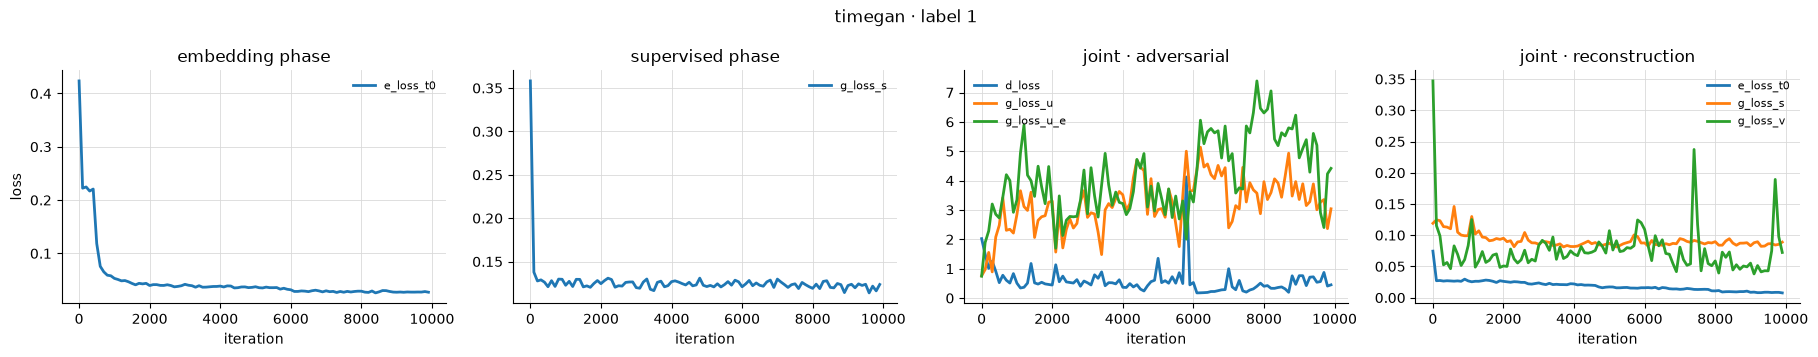

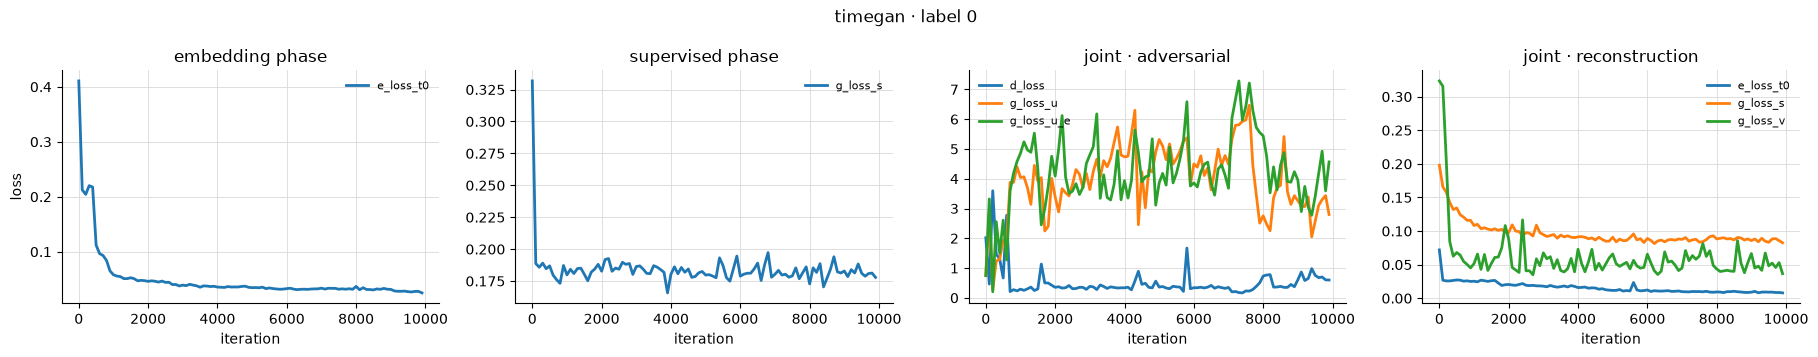

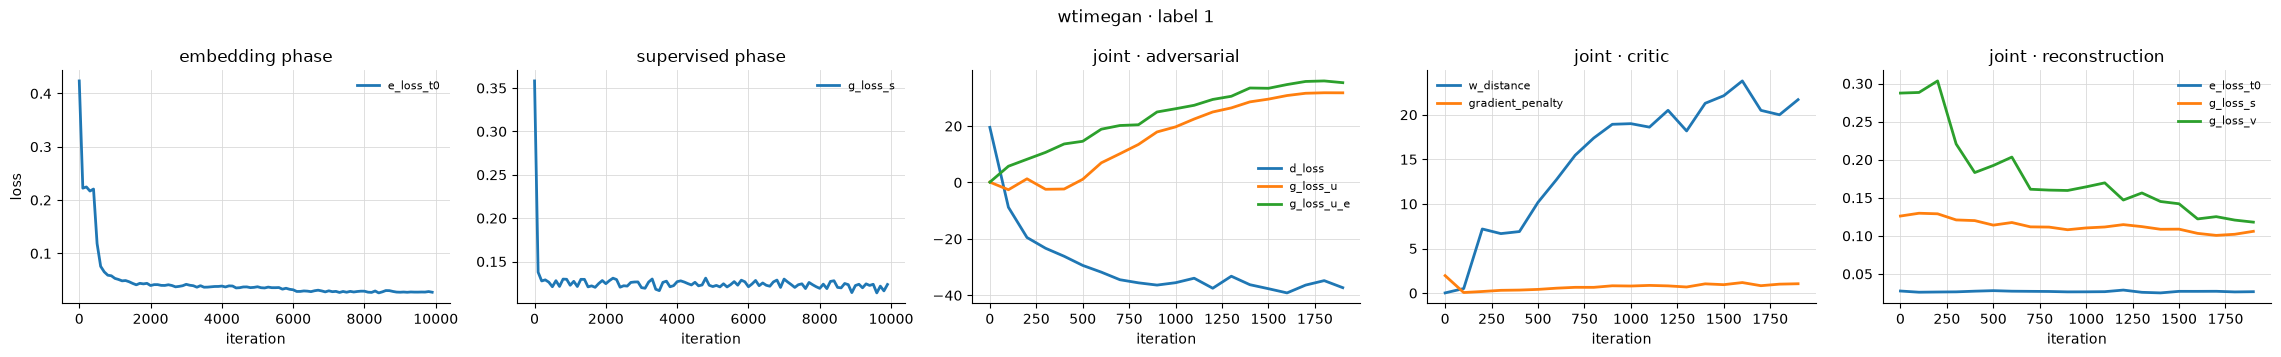

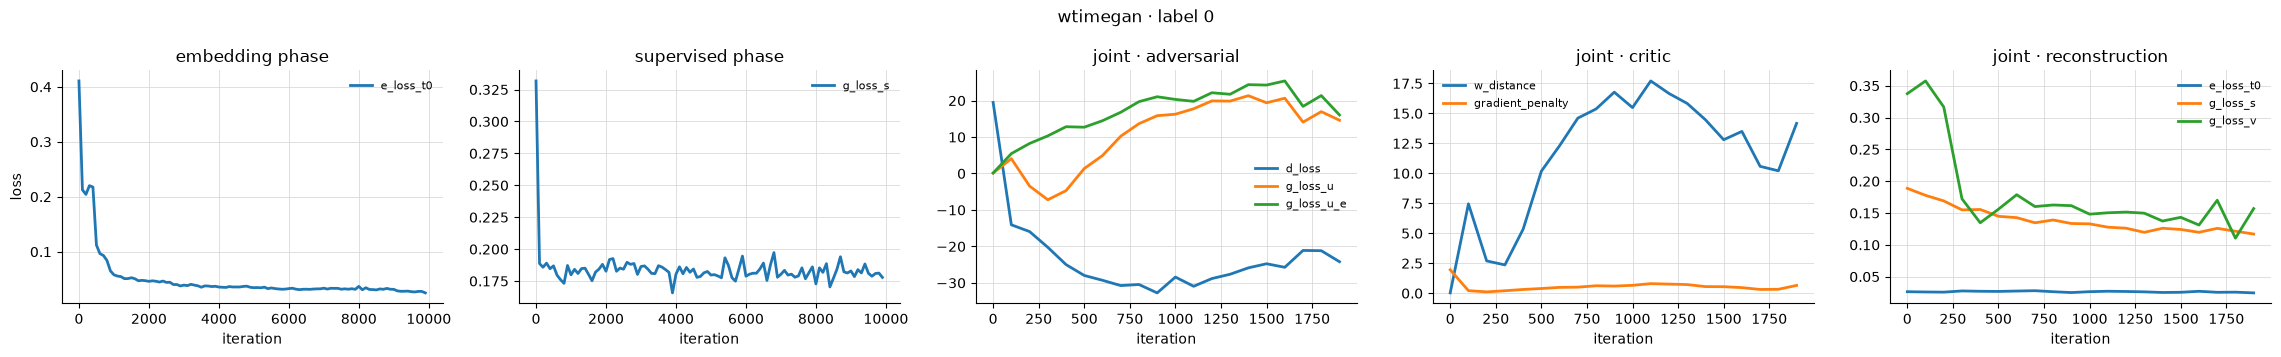

In [6]:
for (gan, label), run in gan_runs.items():
    gp.plot_gan_history(run["history"], f"{gan} · label {label}",
                        save_path=EVAL_DIR / gan / f"history_label{label}.png")
    plt.show()

## 4. Test: generation quality

Every metric compares the synthetic users of one class with the **real `fit` users of that class** (what the GAN learnt from) and reports the same metric for **real `tune` users** (never seen by the GAN) as the real-vs-real reference. A synthetic score close to that reference means the GAN is as close to the training data as a fresh real sample is.

### 4.1 Quantitative metrics

| Metric | What it measures | Better |
|---|---|---|
| **Fréchet distance** (FD) | FID recipe: Fréchet distance between Gaussians fitted to the features of the **w2 churn LSTM** (`h_T`, 64 dims). The Inception network of FID is replaced by the domain classifier, so the distance lives in the space the churn model actually uses | lower; reference = FD(tune, fit) |
| **Discriminative score** | post-hoc GRU trained to separate real from synthetic, `|accuracy - 0.5|` on a held-out 20 % (TimeGAN paper) | 0 = indistinguishable |
| **Predictive score** | GRU trained to predict day `t+1` from days `<= t` on synthetic users, MAE on real `tune` users (train-on-synthetic / test-on-real) | close to the train-on-real MAE |
| **Label fidelity** | mean churn probability the w2 LSTM gives to the synthetic users, and share classified as their class at the w2 threshold. An Inception-Score-like check: does the generated class look like that class to a trained classifier? | close to the real `tune` users of the class |
| **Marginals** | per channel: mean, std, share of non-zero days, Wasserstein-1 / real std | close to real |
| **Per-user aggregates** | active days, payment days, hours, days to expiry at the cutoff, active/inactive switches; two-sample KS | KS close to 0 |

The FD and label-fidelity features use the final w2 LSTM checkpoint and its `development` scaler, exactly as w2 scores March.

In [7]:
w2_lstm, w2_ckpt = bridge.load_w2_classifier("lstm")
W2_THRESHOLD = float(w2_ckpt["threshold"])


def lstm_view(X):
    scaled = bridge.scale(data, X, "development")
    return gq.lstm_features(w2_lstm, scaled, DEVICE), gq.churn_proba(w2_lstm, scaled, DEVICE)


rng = np.random.default_rng(SEED)
quality_rows, marginals, aggregates_tables = [], {}, {}
features = {}   # (source, label) -> LSTM features, reused by the qualitative plots

for label in GAN_LABELS:
    fit_X, tune_X = real["fit", label], real["tune", label]
    n_ref = len(tune_X)
    lo, hi = gq.minmax_fit(fit_X)
    fit_sub = fit_X[rng.choice(len(fit_X), n_ref, replace=False)]

    f_fit, p_fit = lstm_view(fit_sub)
    f_tune, p_tune = lstm_view(tune_X)
    features["real", label] = f_tune
    trtr = gq.predictive_score(fit_X, tune_X, lo=lo, hi=hi, device=DEVICE, seed=SEED)

    candidates = {"real (tune) [reference]": tune_X}
    candidates.update({gan: gan_runs[gan, label]["synthetic"] for gan in GANS})
    for source, X in candidates.items():
        X_sub = X[rng.choice(len(X), n_ref, replace=False)] if len(X) > n_ref else X
        f_x, p_x = (f_tune, p_tune) if source.startswith("real") else lstm_view(X_sub)
        if not source.startswith("real"):
            features[source, label] = f_x
        disc = gq.discriminative_score(fit_X, X_sub, lo=lo, hi=hi, device=DEVICE, seed=SEED)
        pred = trtr if source.startswith("real") else gq.predictive_score(
            X, tune_X, lo=lo, hi=hi, device=DEVICE, seed=SEED)
        quality_rows.append({
            "label": label, "source": source,
            "Fréchet distance (w2 LSTM)": gq.frechet_distance(f_x, f_fit),
            "discriminative score": disc["discriminative score"],
            "predictive MAE (test on real tune)": pred,
            "mean churn proba (w2 LSTM)": p_x.mean(),
            "share classified as its label": ((p_x >= W2_THRESHOLD) == label).mean(),
        })
        if not source.startswith("real"):
            marginals[source, label] = gq.marginal_table(fit_X, X, MODEL_CHANNELS)
            aggregates_tables[source, label] = gq.aggregate_table(fit_X, X, MODEL_CHANNELS)

quality = pd.DataFrame(quality_rows).set_index(["label", "source"])
EVAL_DIR.mkdir(parents=True, exist_ok=True)
quality.to_csv(EVAL_DIR / "quality_summary.csv")
quality.round(4)

Fréchet distance (w2 LSTM)  \
label source                                                
1     real (tune) [reference]                      0.0083   
      timegan                                      0.9363   
      wtimegan                                     0.8374   
0     real (tune) [reference]                      0.0003   
      timegan                                      0.0979   
      wtimegan                                     0.0626   

                               discriminative score  \
label source                                          
1     real (tune) [reference]                0.0153   
      timegan                                0.4572   
      wtimegan                               0.4955   
0     real (tune) [reference]                0.0010   
      timegan                                0.4845   
      wtimegan                               0.4370   

                               predictive MAE (test on real tune)  \
label source                                                        
1     real (tune) [reference]                              0.1079   
      timegan                                              0.0930   
      wtimegan                                             0.1296   
0     real (tune) [reference]                              0.0917   
      timegan                                              0.1049   
      wtimegan                                             0.1214   

                               mean churn proba (w2 LSTM)  \
label source                                                
1     real (tune) [reference]                      0.4764   
      timegan                                      0.7535   
      wtimegan                                     0.3066   
0     real (tune) [reference]                      0.2465   
      timegan                                      0.3368   
      wtimegan                                     0.2697   

                               share classified as its label  
label source                                                  
1     real (tune) [reference]                         0.7230  
      timegan                                         0.9065  
      wtimegan                                        0.4716  
0     real (tune) [reference]                         0.6805  
      timegan                                         0.5936  
      wtimegan                                        0.5602

**Marginals per channel** (synthetic vs real `fit`, same class). `W1 / std real` is comparable across channels; the share of non-zero days checks the event structure (active days, payment days) that the post-processing reconstructs.

In [8]:
for (gan, label), table in marginals.items():
    print(f"\n===== {gan} · label {label} =====")
    table.to_csv(EVAL_DIR / gan / f"marginals_label{label}.csv")
    display(table.round(3))


===== timegan · label 1 =====


,mean real,mean synth,std real,std synth,non-zero real,non-zero synth,W1 / std real
channel,,,,,,,
num_25,0.672,0.639,1.053,1.346,0.363,0.456,0.277
num_50,0.317,0.414,0.614,0.992,0.263,0.456,0.357
num_75,0.246,0.229,0.498,0.428,0.233,0.456,0.199
num_985,0.260,0.320,0.519,0.691,0.240,0.456,0.190
num_100,1.331,1.061,1.633,1.515,0.454,0.456,0.170
num_unq,1.399,1.263,1.654,1.755,0.468,0.456,0.194
total_secs,3.916,3.530,4.267,4.078,0.468,0.456,0.101
active,0.468,0.456,0.499,0.498,0.468,0.456,0.024
tx_count,0.011,0.045,0.090,0.172,0.015,0.064,0.388



===== wtimegan · label 1 =====


,mean real,mean synth,std real,std synth,non-zero real,non-zero synth,W1 / std real
channel,,,,,,,
num_25,0.672,0.730,1.053,1.061,0.363,0.588,0.113
num_50,0.317,0.306,0.614,0.484,0.263,0.588,0.154
num_75,0.246,0.244,0.498,0.375,0.233,0.588,0.193
num_985,0.260,0.280,0.519,0.424,0.240,0.588,0.179
num_100,1.331,1.294,1.633,1.487,0.454,0.588,0.068
num_unq,1.399,1.355,1.654,1.552,0.468,0.588,0.072
total_secs,3.916,4.195,4.267,3.969,0.468,0.588,0.111
active,0.468,0.588,0.499,0.492,0.468,0.588,0.241
tx_count,0.011,0.001,0.090,0.030,0.015,0.002,0.108



===== timegan · label 0 =====


,mean real,mean synth,std real,std synth,non-zero real,non-zero synth,W1 / std real
channel,,,,,,,
num_25,0.976,1.108,1.177,1.101,0.506,0.659,0.170
num_50,0.464,0.519,0.709,0.763,0.374,0.659,0.114
num_75,0.361,0.422,0.577,0.589,0.334,0.659,0.156
num_985,0.383,0.391,0.601,0.647,0.345,0.659,0.155
num_100,1.842,1.751,1.680,1.528,0.617,0.659,0.087
num_unq,1.934,1.887,1.686,1.576,0.632,0.659,0.065
total_secs,5.342,5.404,4.194,4.035,0.632,0.659,0.055
active,0.632,0.659,0.482,0.474,0.632,0.659,0.056
tx_count,0.016,0.019,0.105,0.113,0.023,0.026,0.030



===== wtimegan · label 0 =====


,mean real,mean synth,std real,std synth,non-zero real,non-zero synth,W1 / std real
channel,,,,,,,
num_25,0.976,1.129,1.177,1.260,0.506,0.639,0.129
num_50,0.464,0.546,0.709,0.625,0.374,0.639,0.197
num_75,0.361,0.462,0.577,0.510,0.334,0.639,0.243
num_985,0.383,0.546,0.601,0.567,0.345,0.639,0.302
num_100,1.842,1.829,1.680,1.694,0.617,0.639,0.064
num_unq,1.934,1.898,1.686,1.724,0.632,0.639,0.054
total_secs,5.342,5.300,4.194,4.200,0.632,0.639,0.038
active,0.632,0.639,0.482,0.480,0.632,0.639,0.013
tx_count,0.016,0.001,0.105,0.031,0.023,0.002,0.139


**Per-user aggregates.** Business-level checks: a realistic synthetic churner should have the activity, payment and expiry profile of real churners, not only the right daily averages.

In [9]:
for (gan, label), table in aggregates_tables.items():
    print(f"\n===== {gan} · label {label} =====")
    table.to_csv(EVAL_DIR / gan / f"aggregates_label{label}.csv")
    display(table.round(3))


===== timegan · label 1 =====


,mean real,mean synth,KS
aggregate,,,
active days,42.130,41.055,0.422
active days (last 30),15.524,14.197,0.422
payment days,1.391,5.804,0.370
log hours listened,3.751,2.302,0.438
days to expire at cutoff,24.062,104.612,0.371
active-day switches,16.798,9.073,0.552



===== wtimegan · label 1 =====


,mean real,mean synth,KS
aggregate,,,
active days,42.130,52.958,0.567
active days (last 30),15.524,16.946,0.437
payment days,1.391,0.167,0.567
log hours listened,3.751,4.260,0.505
days to expire at cutoff,24.062,46.065,0.251
active-day switches,16.798,26.254,0.684



===== timegan · label 0 =====


,mean real,mean synth,KS
aggregate,,,
active days,56.907,59.278,0.271
active days (last 30),20.322,20.115,0.185
payment days,2.052,2.384,0.300
log hours listened,4.450,3.859,0.201
days to expire at cutoff,13.270,18.291,0.243
active-day switches,18.226,12.866,0.274



===== wtimegan · label 0 =====


,mean real,mean synth,KS
aggregate,,,
active days,56.907,57.516,0.451
active days (last 30),20.322,21.260,0.489
payment days,2.052,0.184,0.699
log hours listened,4.450,4.196,0.364
days to expire at cutoff,13.270,-7.043,0.343
active-day switches,18.226,10.049,0.478


### 4.2 Qualitative assessment

1. **PCA and t-SNE** of the w2 LSTM features (as in the TimeGAN paper): synthetic points should cover the same regions as the real ones, not a sub-region (mode collapse) nor a separate cluster.
2. **Daily profiles**: mean and 25-75 % band of every channel per day. Shows whether the GAN reproduces the temporal shape (e.g. activity decaying towards the cutoff for churners, the expiry countdown).
3. **Individual users**: heatmaps of single real and synthetic users (rows = days, columns = channels). Realistic users have runs of active days, sparse payment days and a consistent payment state.
4. **Histograms of the per-user aggregates.**

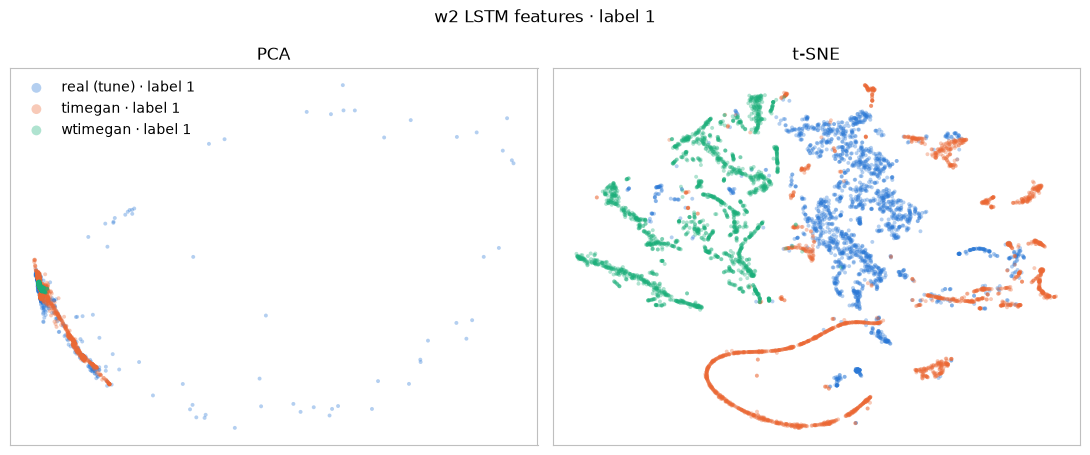

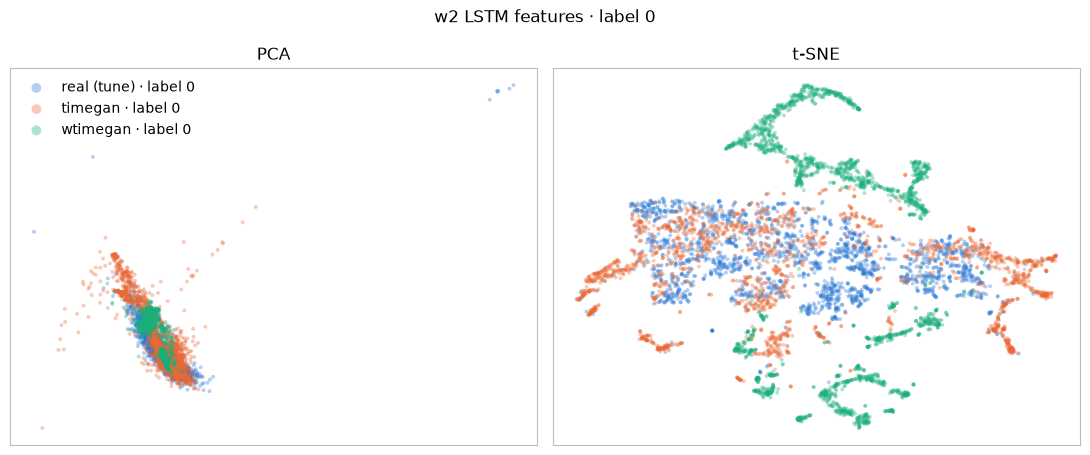

In [10]:
for label in GAN_LABELS:
    feats = {f"real (tune) · label {label}": features["real", label]}
    feats.update({f"{gan} · label {label}": features[gan, label] for gan in GANS})
    gp.plot_embedding_2d(feats, f"w2 LSTM features · label {label}", seed=SEED,
                         save_path=EVAL_DIR / f"embedding_label{label}.png")
    plt.show()

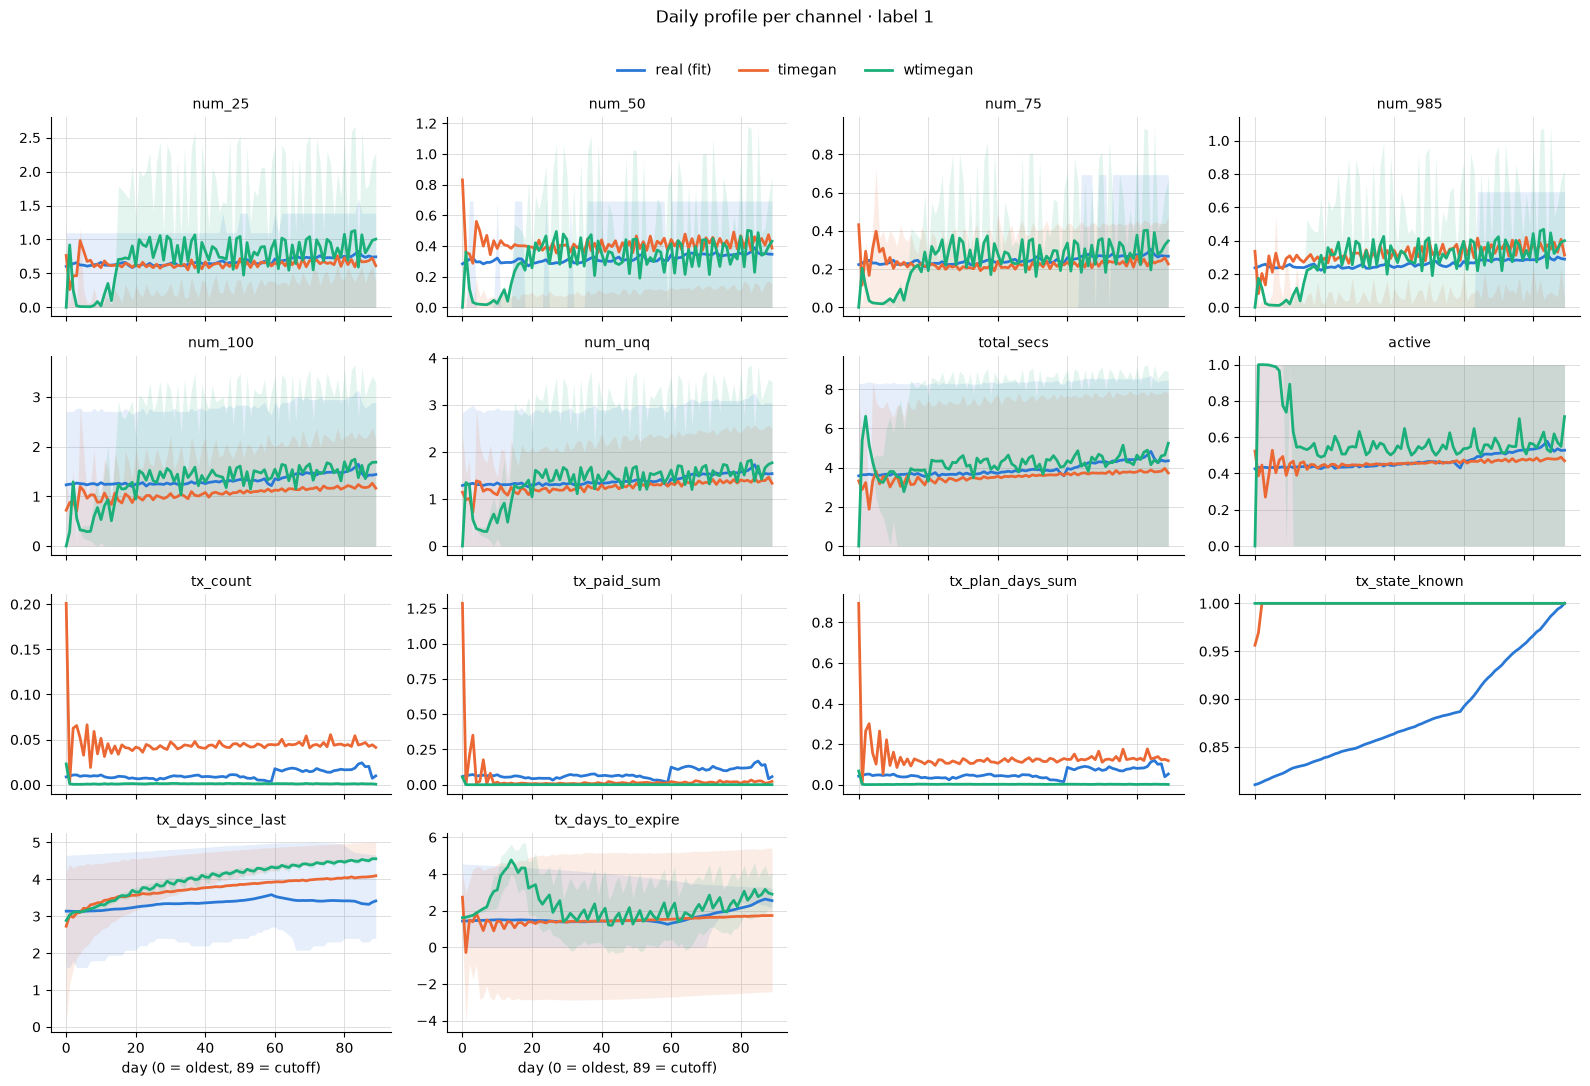

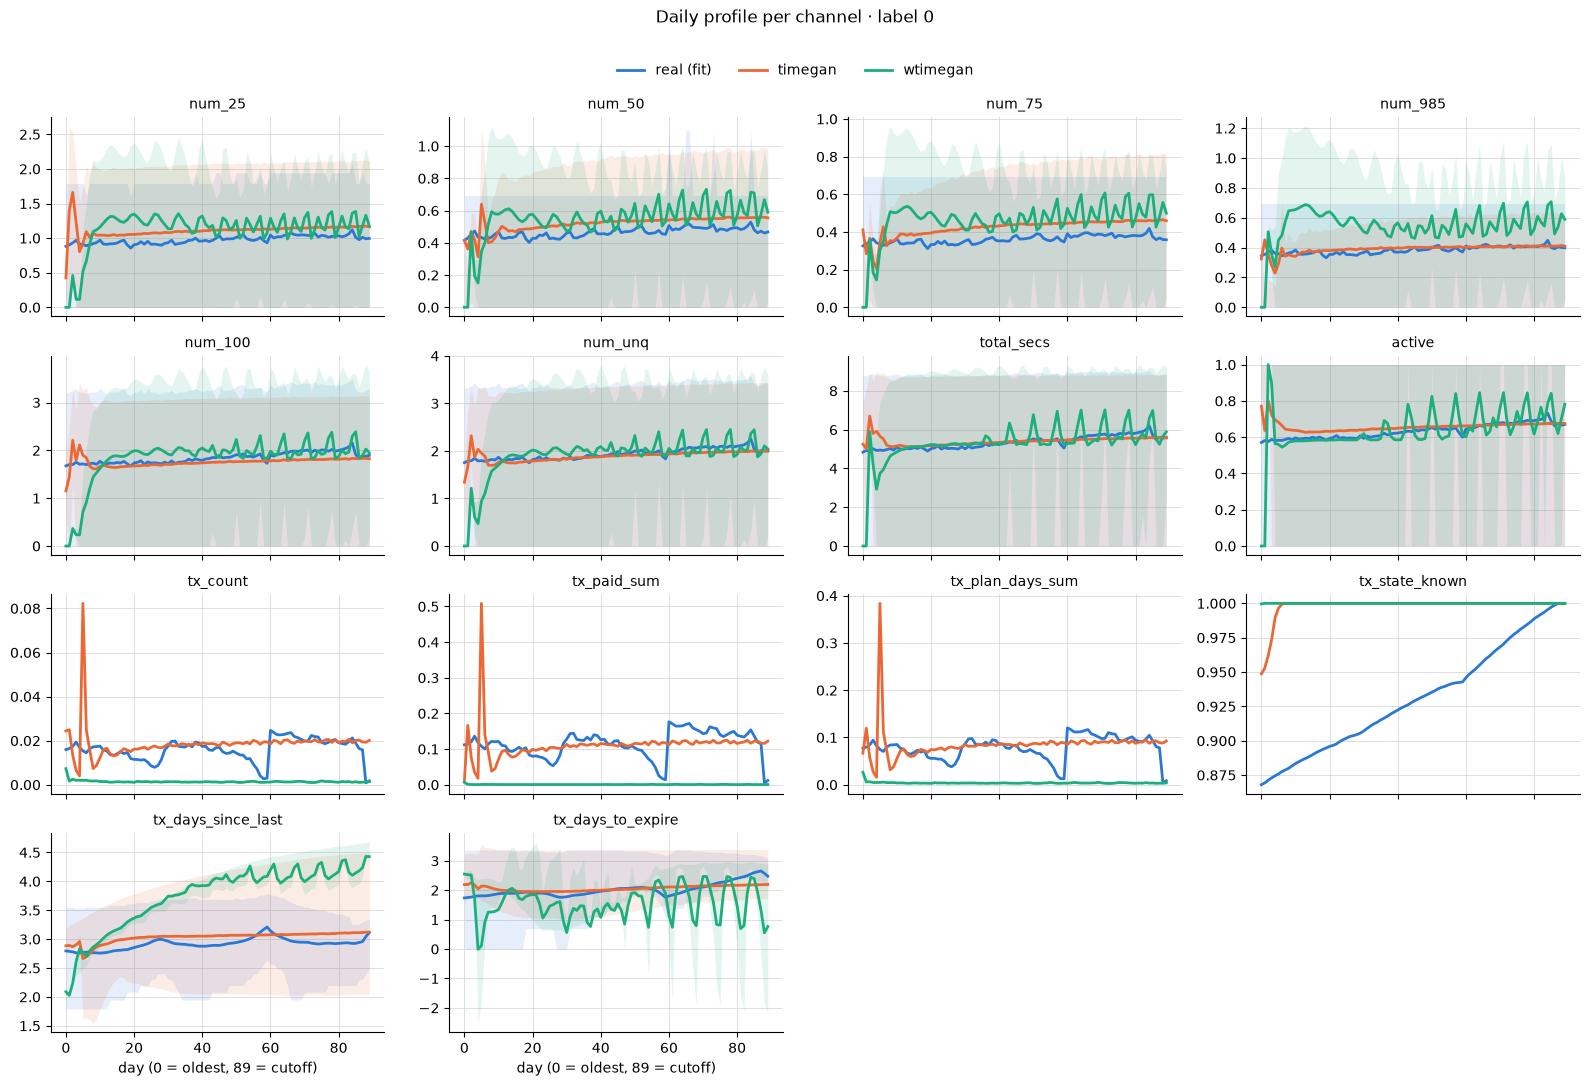

In [11]:
for label in GAN_LABELS:
    sources = {"real (fit)": real["fit", label]}
    sources.update({gan: gan_runs[gan, label]["synthetic"] for gan in GANS})
    gp.plot_daily_profiles(sources, MODEL_CHANNELS, f"Daily profile per channel · label {label}",
                           save_path=EVAL_DIR / f"daily_profiles_label{label}.png")
    plt.show()

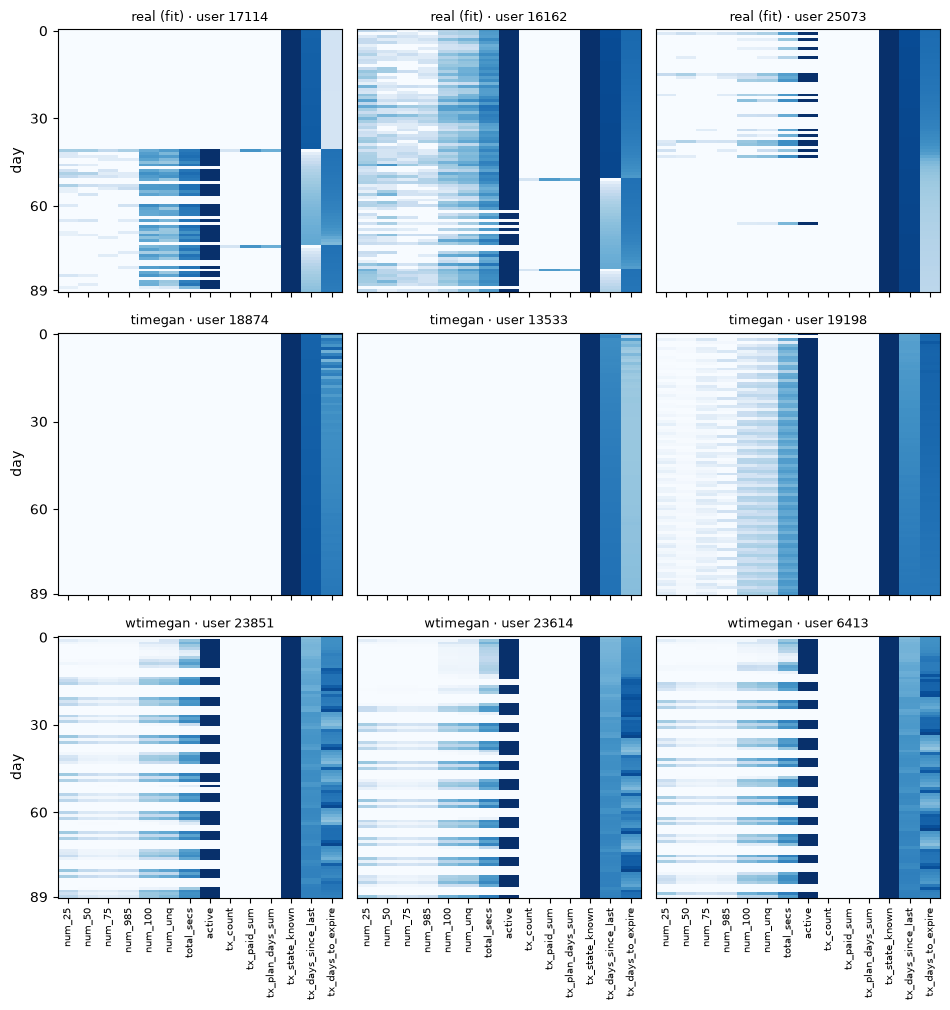

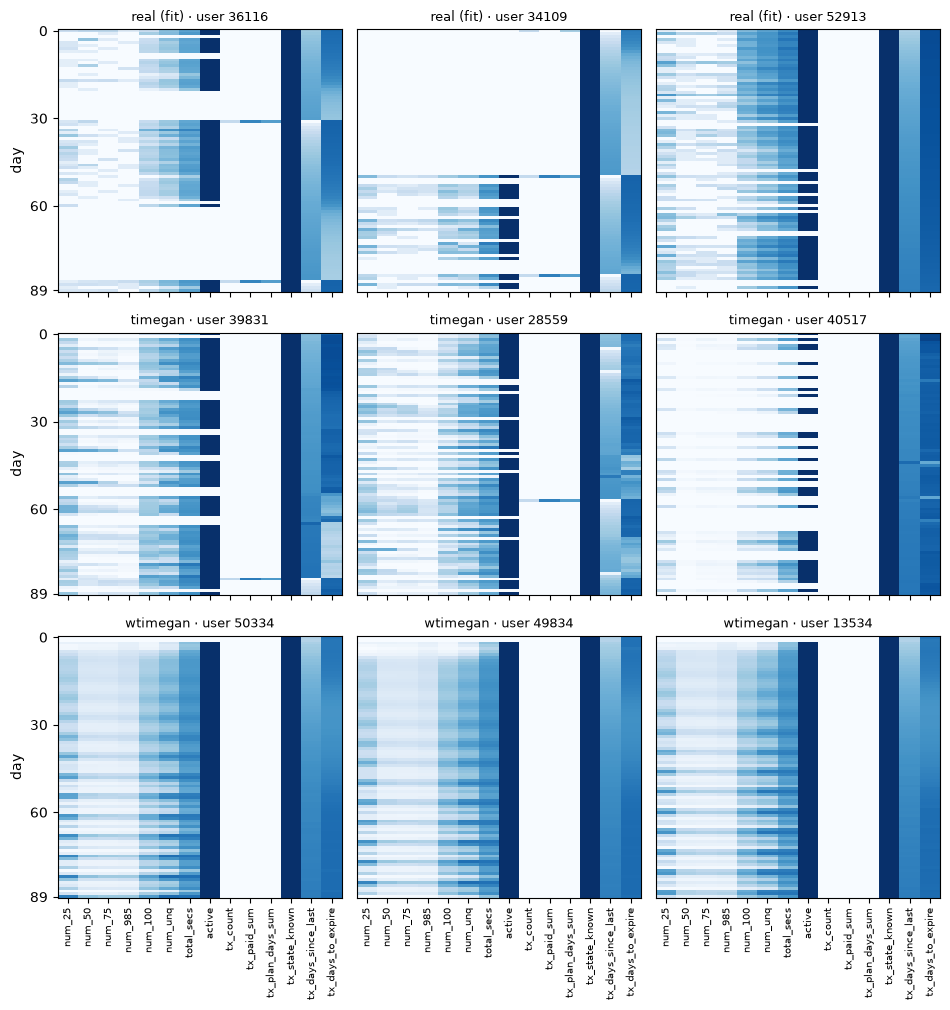

In [12]:
for label in GAN_LABELS:
    sources = {"real (fit)": real["fit", label]}
    sources.update({gan: gan_runs[gan, label]["synthetic"] for gan in GANS})
    gp.plot_user_slices(sources, MODEL_CHANNELS, n_users=3, seed=SEED,
                        save_path=EVAL_DIR / f"user_slices_label{label}.png")
    plt.show()

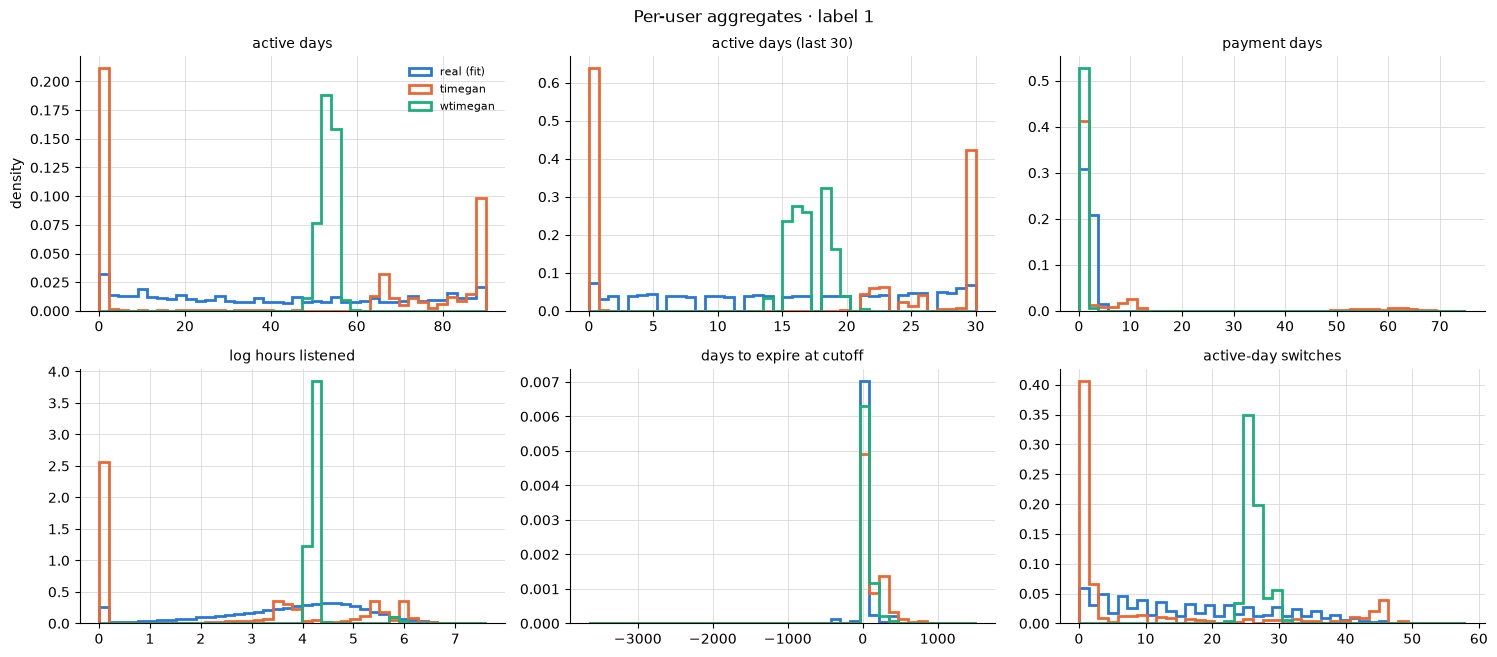

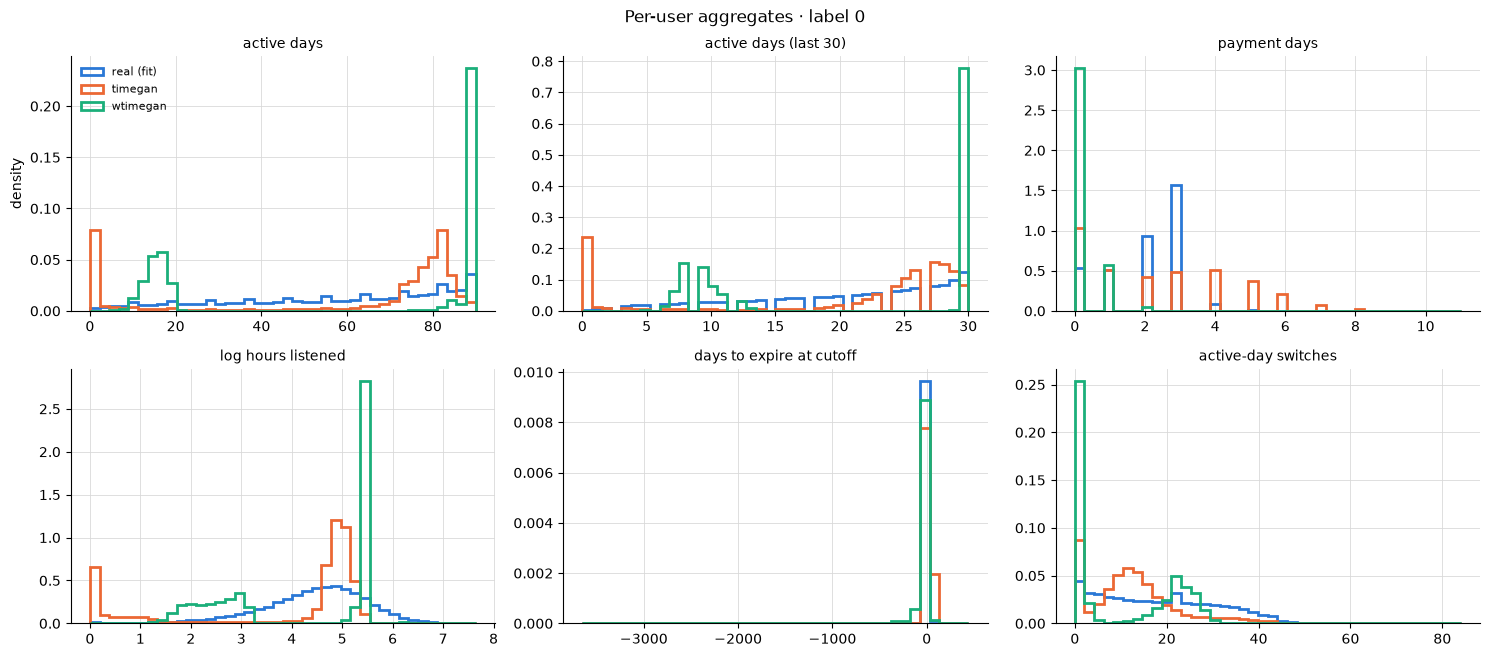

In [13]:
for label in GAN_LABELS:
    aggs = {"real (fit)": gq.user_aggregates(real["fit", label], MODEL_CHANNELS)}
    aggs.update({gan: gq.user_aggregates(gan_runs[gan, label]["synthetic"], MODEL_CHANNELS)
                 for gan in GANS})
    gp.plot_aggregate_hists(aggs, save_path=EVAL_DIR / f"aggregates_label{label}.png")
    plt.suptitle(f"Per-user aggregates · label {label}", y=1.02)
    plt.show()

### 4.3 Domain checks for the trajectory model

The trajectory model learns **when** a user pays from the state channels: real manual payers pay around their expiry day. TimeGAN generates the 14 channels jointly but nothing forces a generated payment to update the generated state, so a synthetic user can pay on a random day or keep an expiry countdown that no payment resets. That is harmless for marginals but teaches the trajectory model the wrong rule.

Two checks, on real `fit`, real `tune` (reference), each GAN as post-processed and each GAN with the **state rebuilt** from its payments (`postprocess(..., rebuild_state=True)` on `raw.npy`):

1. **Event-state consistency**: share of days that follow the w2 builder rules (real users: 93-100 %), the mean plan days and amount on payment days, and the payment and activity rates of the last 7 days (the forecast horizon).
2. **Payment timing**: share of payment days within 3 days of the expiry known the day before, and the payment rate against the day relative to the expiry (0 = expiry day), the same alignment as `plot_pay_by_expiry` in w2.

How to read the two variants:

- **generated state** is what TimeGAN produced. If check 1 fails (payments that do not reset `since_last`, countdowns that ignore payments), these users are impossible, and the payment-timing curve can look right or wrong by accident because it uses an expiry no payment ever set.
- **state rebuilt** is internally consistent by construction, so check 2 becomes the honest test of whether the GAN learnt *when* users pay.

Rule: if the generated state fails check 1, set `REBUILD_STATE = True` in section 1 and re-run from there (no GAN retraining). Whatever the variant, a low share of payments near the expiry means the GAN did not learn renewal timing, and the trajectory bridge (5.2) should not be expected to improve `pay`.

In [14]:
variants = {}   # (source, label) -> users
for label in GAN_LABELS:
    variants["real (fit)", label] = real["fit", label]
    variants["real (tune)", label] = real["tune", label]
    for gan in GANS:
        raw, upper = gan_runs[gan, label]["raw"], real["fit", label].max(axis=(0, 1))
        variants[f"{gan} (generated state)", label] = postprocess(raw, specs, seed=SEED, upper=upper)
        variants[f"{gan} (state rebuilt)", label] = postprocess(raw, specs, seed=SEED, rebuild_state=True,
                                                                 upper=upper)

consistency = pd.DataFrame(
    [{"label": label, "source": source,
      **gq.payment_state_consistency(X, MODEL_CHANNELS),
      "payments within 3 days of expiry": gq.payments_near_expiry(X, MODEL_CHANNELS)}
     for (source, label), X in variants.items()]
).set_index(["label", "source"])
consistency.to_csv(EVAL_DIR / "trajectory_consistency.csv")
consistency.round(3)

pay day: since_last = 0  \
label source                                                
1     real (fit)                                    1.000   
      real (tune)                                   1.000   
      timegan (generated state)                     0.978   
      timegan (state rebuilt)                       1.000   
      wtimegan (generated state)                    0.000   
      wtimegan (state rebuilt)                      1.000   
0     real (fit)                                    1.000   
      real (tune)                                   1.000   
      timegan (generated state)                     0.947   
      timegan (state rebuilt)                       1.000   
      wtimegan (generated state)                    0.000   
      wtimegan (state rebuilt)                      1.000   

                                  no pay: since_last + 1  \
label source                                               
1     real (fit)                                   1.000   
      real (tune)                                  1.000   
      timegan (generated state)                    0.834   
      timegan (state rebuilt)                      1.000   
      wtimegan (generated state)                   0.310   
      wtimegan (state rebuilt)                     1.000   
0     real (fit)                                   1.000   
      real (tune)                                  1.000   
      timegan (generated state)                    0.862   
      timegan (state rebuilt)                      1.000   
      wtimegan (generated state)                   0.593   
      wtimegan (state rebuilt)                     1.000   

                                  no pay: to_expire - 1  \
label source                                              
1     real (fit)                                  1.000   
      real (tune)                                 1.000   
      timegan (generated state)                   0.586   
      timegan (state rebuilt)                     1.000   
      wtimegan (generated state)                  0.380   
      wtimegan (state rebuilt)                    1.000   
0     real (fit)                                  1.000   
      real (tune)                                 1.000   
      timegan (generated state)                   0.473   
      timegan (state rebuilt)                     1.000   
      wtimegan (generated state)                  0.476   
      wtimegan (state rebuilt)                    1.000   

                                  pay day: to_expire = max(prev-1,0) + plan  \
label source                                                                  
1     real (fit)                                                      0.933   
      real (tune)                                                     0.929   
      timegan (generated state)                                       0.215   
      timegan (state rebuilt)                                         1.000   
      wtimegan (generated state)                                      0.139   
      wtimegan (state rebuilt)                                        1.000   
0     real (fit)                                                      0.975   
      real (tune)                                                     0.974   
      timegan (generated state)                                       0.126   
      timegan (state rebuilt)                                         1.000   
      wtimegan (generated state)                                      0.042   
      wtimegan (state rebuilt)                                        1.000   

                                  payment day rate  pay day: mean plan days  \
label source                                                                  
1     real (fit)                             0.015                   40.972   
      real (tune)                            0.015                   41.788   
      timegan (generated state)              0.064                   10.474   
      tim

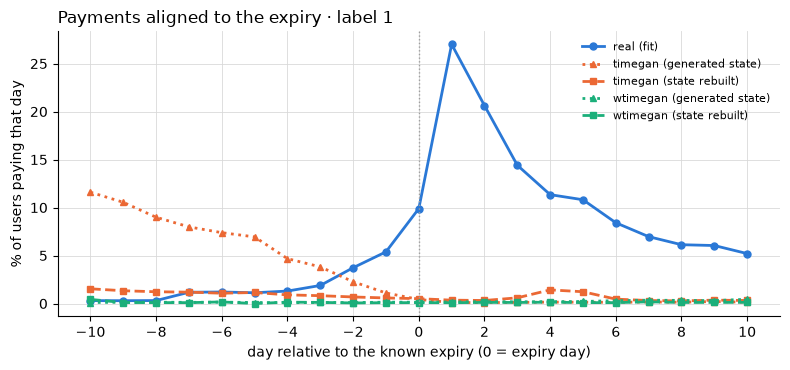

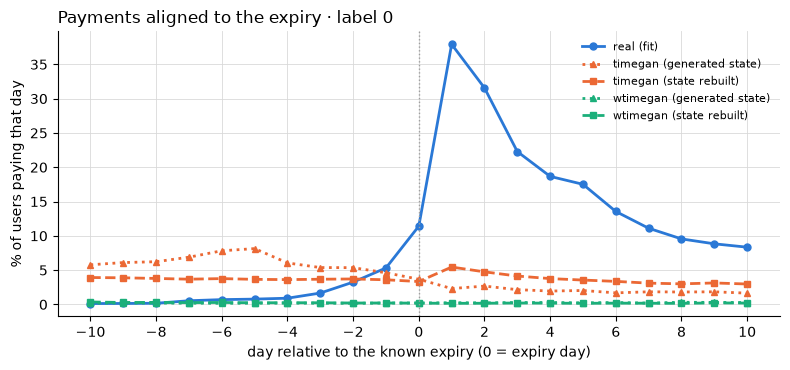

In [15]:
for label in GAN_LABELS:
    curves = {source: gq.pay_by_expiry(X, MODEL_CHANNELS)[0]
              for (source, lab), X in variants.items() if lab == label and source != "real (tune)"}
    gp.plot_pay_by_expiry(curves, f"Payments aligned to the expiry · label {label}",
                          save_path=EVAL_DIR / f"pay_by_expiry_label{label}.png")
    plt.show()

## 5. Bridge w2 -> w5: do the synthetic users help?

### 5.1 Churn classifiers

The w2 classifiers (LSTM and GRU, **w2 best hyper-parameters**, no new tuning) are retrained under one protocol where only the training rows change:

| Scenario | Training rows |
|---|---|
| `baseline` | real `fit` (w2 protocol without the final refit) |
| `<gan> +50% churn` | real `fit` + synthetic churners = 50 % of the real `fit` churners |
| `<gan> +100% churn` | real `fit` + synthetic churners = 100 % (classes almost balanced) |
| `<gan> TSTR` | synthetic only, both classes, same size and churn rate as `fit` (train-on-synthetic, test-on-real) |

In every scenario: early stopping on real `stop`, threshold selected on real `tune` (max churn F1, as in w2), and **real March is scored once**. The synthetic users go through the w2 `fit` scaler, fitted on real users only.

The baseline is retrained here, rather than read from w2, because w2 refits on all of February: comparing against it would mix the effect of the synthetic data with that of 25 % more real data.

Adding churners shifts the training prior, so **log-loss and Brier** are expected to worsen (the probabilities are calibrated to a higher churn rate). The ranking metrics (**AUC-ROC, AUC-PR**) and F1 at the tune threshold are the fair test of whether the synthetic data adds information.

In [16]:
fit_rows = data.rows("fit")
n_fit_churn = int(data.y_all[fit_rows].sum())
n_fit_stay = len(fit_rows) - n_fit_churn

bridge_runs = {m: {} for m in BRIDGE_MODELS}
bridge_tunes = {m: {} for m in BRIDGE_MODELS}

for model_name in BRIDGE_MODELS:
    print(f"\n===== {model_name.upper()} · baseline =====")
    bridge_runs[model_name]["baseline"], bridge_tunes[model_name]["baseline"] = bridge.run_scenario(
        data, model_name, fit_rows, device=DEVICE, seed=SEED)

for gan in GANS:
    synthetic = {label: gan_runs[gan, label]["synthetic"] for label in GAN_LABELS}
    data_aug, synth_rows = bridge.augment(data, synthetic)
    scenarios = {
        f"{gan} +{int(f * 100)}% churn": np.concatenate(
            [fit_rows, bridge.take(synth_rows[1], int(round(f * n_fit_churn)), seed=SEED)])
        for f in AUG_FRACTIONS
    }
    if 0 in synth_rows:
        scenarios[f"{gan} TSTR"] = np.concatenate([
            bridge.take(synth_rows[1], min(n_fit_churn, len(synth_rows[1])), seed=SEED),
            bridge.take(synth_rows[0], min(n_fit_stay, len(synth_rows[0])), seed=SEED)])
    for model_name in BRIDGE_MODELS:
        for scenario, rows in scenarios.items():
            print(f"\n===== {model_name.upper()} · {scenario} ({len(rows):,} rows) =====")
            bridge_runs[model_name][scenario], bridge_tunes[model_name][scenario] = bridge.run_scenario(
                data_aug, model_name, rows, device=DEVICE, seed=SEED)
    del data_aug


===== LSTM · baseline =====
scaled tensor for phase 'fit' cached in 5.4s

===== GRU · baseline =====

===== LSTM · timegan +50% churn (97,288 rows) =====
loaded raw tensor into RAM: (309435, 90, 14) float16 in 0.4s
scaled tensor for phase 'fit' cached in 7.8s

===== LSTM · timegan +100% churn (110,761 rows) =====

===== LSTM · timegan TSTR (83,814 rows) =====

===== GRU · timegan +50% churn (97,288 rows) =====

===== GRU · timegan +100% churn (110,761 rows) =====

===== GRU · timegan TSTR (83,814 rows) =====

===== LSTM · wtimegan +50% churn (97,288 rows) =====
loaded raw tensor into RAM: (309435, 90, 14) float16 in 0.4s
scaled tensor for phase 'fit' cached in 7.7s

===== LSTM · wtimegan +100% churn (110,761 rows) =====

===== LSTM · wtimegan TSTR (83,814 rows) =====

===== GRU · wtimegan +50% churn (97,288 rows) =====

===== GRU · wtimegan +100% churn (110,761 rows) =====

===== GRU · wtimegan TSTR (83,814 rows) =====


#### Results on real March

Metrics at each scenario's own `tune` threshold. Then, for each scenario, the **paired bootstrap** against the baseline (1,000 resamples of the March users; a difference is significant when its 95 % interval excludes 0) and the **DeLong** test for AUC-ROC.

In [17]:
BRIDGE_DIR.mkdir(parents=True, exist_ok=True)
for model_name in BRIDGE_MODELS:
    print(f"\n===== {model_name.upper()} =====")
    table = bridge.scenario_table(bridge_runs[model_name], bridge_tunes[model_name])
    table.to_csv(BRIDGE_DIR / f"scenarios_{model_name}.csv")
    display(table.round(4))


===== LSTM =====


,train users,train churn rate,best epoch,AUC-ROC,AUC-PR,F1,precision,recall,log-loss,brier,threshold
scenario,,,,,,,,,,,
baseline,83814,0.3215,13,0.7678,0.7057,0.6707,0.6390,0.7057,0.5860,0.2015,0.30
timegan +50% churn,97288,0.4155,12,0.7668,0.6991,0.6745,0.6466,0.7050,0.5801,0.1983,0.33
timegan +100% churn,110761,0.4866,12,0.7693,0.7049,0.6782,0.6339,0.7291,0.5871,0.2009,0.29
timegan TSTR,83814,0.3215,2,0.5874,0.4748,0.2741,0.5326,0.1846,2.5064,0.4024,0.01
wtimegan +50% churn,97288,0.4155,10,0.7706,0.7097,0.6734,0.6429,0.7070,0.5732,0.1954,0.33
wtimegan +100% churn,110761,0.4866,11,0.7667,0.6982,0.6742,0.6456,0.7054,0.5829,0.1997,0.32
wtimegan TSTR,83814,0.3215,1,0.6435,0.5527,0.5601,0.4881,0.6572,3.8020,0.3802,0.01



===== GRU =====


,train users,train churn rate,best epoch,AUC-ROC,AUC-PR,F1,precision,recall,log-loss,brier,threshold
scenario,,,,,,,,,,,
baseline,83814,0.3215,10,0.7705,0.7039,0.6767,0.6519,0.7034,0.5824,0.1996,0.31
timegan +50% churn,97288,0.4155,9,0.7611,0.6913,0.6764,0.6192,0.7453,0.5890,0.2022,0.28
timegan +100% churn,110761,0.4866,2,0.7747,0.7131,0.6679,0.6554,0.6810,0.5831,0.1995,0.30
timegan TSTR,83814,0.3215,1,0.6466,0.5636,0.4413,0.6571,0.3322,2.3636,0.3693,0.01
wtimegan +50% churn,97288,0.4155,4,0.7712,0.7039,0.6824,0.6427,0.7274,0.5743,0.1963,0.32
wtimegan +100% churn,110761,0.4866,4,0.7761,0.7159,0.6766,0.6694,0.6841,0.5699,0.1947,0.34
wtimegan TSTR,83814,0.3215,1,0.5836,0.4861,0.5498,0.4462,0.7159,5.2923,0.4592,0.01


In [18]:
for model_name in BRIDGE_MODELS:
    print(f"\n===== {model_name.upper()}: scenario - baseline =====")
    versus = bridge.versus_baseline(bridge_runs[model_name], bridge_tunes[model_name], "baseline")
    versus.to_csv(BRIDGE_DIR / f"versus_baseline_{model_name}.csv")
    display(versus.round(4))


===== LSTM: scenario - baseline =====


Δ vs baseline              Δ IC95  significant  \
scenario             metric                                                     
timegan +50% churn   AUC-ROC         -0.0010  [-0.0018, -0.0003]         True   
                     AUC-PR          -0.0065  [-0.0076, -0.0053]         True   
                     F1               0.0038    [0.0022, 0.0055]         True   
                     Log-loss        -0.0059  [-0.0067, -0.0052]         True   
timegan +100% churn  AUC-ROC          0.0015    [0.0007, 0.0023]         True   
                     AUC-PR          -0.0007   [-0.0018, 0.0005]        False   
                     F1               0.0075    [0.0059, 0.0091]         True   
                     Log-loss         0.0011    [0.0003, 0.0018]         True   
timegan TSTR         AUC-ROC         -0.1805  [-0.1846, -0.1763]         True   
                     AUC-PR          -0.2309  [-0.2354, -0.2262]         True   
                     F1              -0.3965  [-0.4021, -0.3915]         True   
                     Log-loss         1.9204    [1.9037, 1.9365]         True   
wtimegan +50% churn  AUC-ROC          0.0028    [0.0021, 0.0034]         True   
                     AUC-PR           0.0041    [0.0031, 0.0052]         True   
                     F1               0.0028    [0.0014, 0.0042]         True   
                     Log-loss        -0.0128  [-0.0135, -0.0121]         True   
wtimegan +100% churn AUC-ROC         -0.0011  [-0.0019, -0.0003]         True   
                     AUC-PR          -0.0075  [-0.0088, -0.0063]         True   
                     F1               0.0035    [0.0020, 0.0052]         True   
                     Log-loss        -0.0031  [-0.0040, -0.0022]         True   
wtimegan TSTR        AUC-ROC         -0.1243  [-0.1278, -0.1204]         True   
                     AUC-PR          -0.1529  [-0.1574, -0.1480]         True   
                     F1              -0.1105  [-0.1141, -0.1063]         True   
                     Log-loss         3.2159    [3.1852, 3.2482]         True   

                               DeLong p (AUC-ROC)  
scenario             metric                        
timegan +50% churn   AUC-ROC               0.0066  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
timegan +100% churn  AUC-ROC               0.0002  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
timegan TSTR         AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
wtimegan +50% churn  AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
wtimegan +100% churn AUC-ROC               0.0069  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
wtimegan TSTR        AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN


===== GRU: scenario - baseline =====


Δ vs baseline              Δ IC95  significant  \
scenario             metric                                                     
timegan +50% churn   AUC-ROC         -0.0094  [-0.0102, -0.0086]         True   
                     AUC-PR          -0.0126  [-0.0136, -0.0116]         True   
                     F1              -0.0003   [-0.0019, 0.0014]        False   
                     Log-loss         0.0066    [0.0059, 0.0074]         True   
timegan +100% churn  AUC-ROC          0.0042    [0.0033, 0.0051]         True   
                     AUC-PR           0.0092    [0.0079, 0.0106]         True   
                     F1              -0.0088  [-0.0106, -0.0069]         True   
                     Log-loss         0.0008   [-0.0001, 0.0017]        False   
timegan TSTR         AUC-ROC         -0.1239  [-0.1278, -0.1199]         True   
                     AUC-PR          -0.1403  [-0.1452, -0.1352]         True   
                     F1              -0.2354  [-0.2399, -0.2308]         True   
                     Log-loss         1.7812    [1.7637, 1.7988]         True   
wtimegan +50% churn  AUC-ROC          0.0007   [-0.0002, 0.0016]        False   
                     AUC-PR          -0.0001   [-0.0012, 0.0012]        False   
                     F1               0.0057    [0.0041, 0.0074]         True   
                     Log-loss        -0.0081  [-0.0090, -0.0072]         True   
wtimegan +100% churn AUC-ROC          0.0056    [0.0048, 0.0065]         True   
                     AUC-PR           0.0119    [0.0109, 0.0131]         True   
                     F1              -0.0000   [-0.0018, 0.0018]        False   
                     Log-loss        -0.0124  [-0.0133, -0.0116]         True   
wtimegan TSTR        AUC-ROC         -0.1869  [-0.1909, -0.1824]         True   
                     AUC-PR          -0.2178  [-0.2226, -0.2125]         True   
                     F1              -0.1269  [-0.1309, -0.1227]         True   
                     Log-loss         4.7100    [4.6726, 4.7483]         True   

                               DeLong p (AUC-ROC)  
scenario             metric                        
timegan +50% churn   AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
timegan +100% churn  AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
timegan TSTR         AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
wtimegan +50% churn  AUC-ROC               0.1419  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
wtimegan +100% churn AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN  
wtimegan TSTR        AUC-ROC               0.0000  
                     AUC-PR                   NaN  
                     F1                       NaN  
                     Log-loss                 NaN

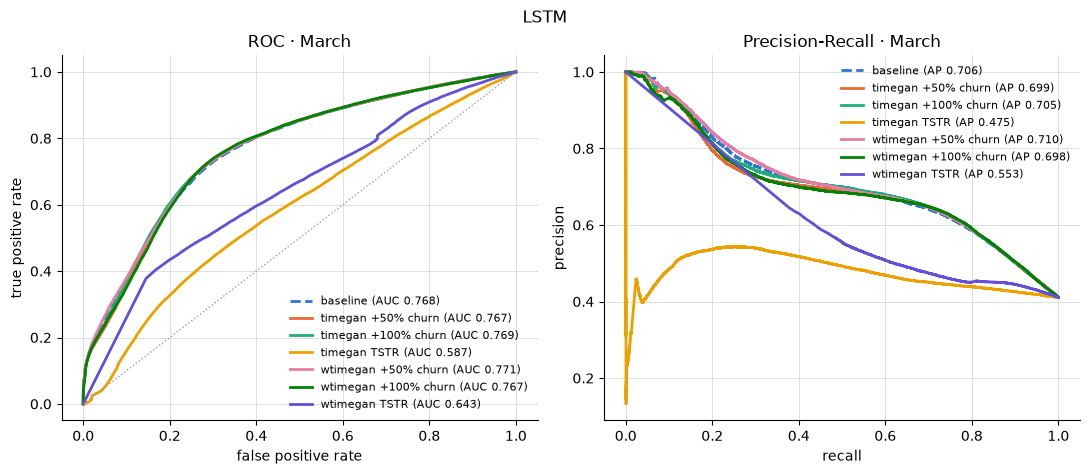

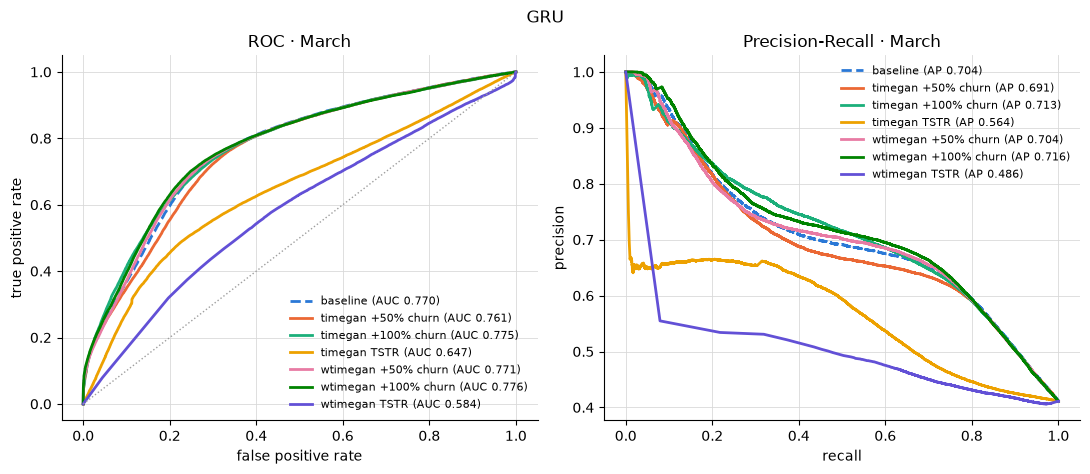

In [19]:
for model_name in BRIDGE_MODELS:
    runs = bridge_runs[model_name]
    palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
    colors = {name: palette[i % len(palette)] for i, name in enumerate(runs)}
    gp.plot_scenarios_roc_pr(runs, colors, save_path=BRIDGE_DIR / f"roc_pr_{model_name}.png")
    plt.suptitle(model_name.upper(), y=1.02)
    plt.show()

### 5.2 Trajectory models

The w2 trajectory models (`trajectory_models/`, LSTM and GRU with their **w2 best hyper-parameters and loss weights**) read days 0-82 and forecast 11 targets for days 83-89: the 7 listening amounts, `active`, `pay` and the paid amount / plan days. There is **no churn label**: each synthetic user supplies its own input and targets, so the synthetic set must look like the real population. Synthetic users of both classes are mixed at the churn rate of `fit` (32 %).

| Scenario | Training rows |
|---|---|
| `baseline` | real `fit` |
| `<gan> +50%` / `+100%` | real `fit` + synthetic users = 50 % / 100 % of `fit`, real churn mix |
| `<gan> TSTR` | synthetic only, same size and mix as `fit` |

Same protocol as the classifiers: early stopping on real `stop` (weighted composite loss), `fit` scaler, real March scored once with the w2 `evaluate_trajectories`. The baseline is retrained here because w2 refits on all of February.

Metrics (as in w2): listening MAE and skill vs persistence (log1p units, lower MAE is better), AUC/AP of `active` and `pay` per day, AP of paying within the week, and the error of the paid amount on real payment days. The paired bootstrap resamples **March users** (all 7 days of a user move together).

In [20]:
fit_churn_rate = float(data.y_all[fit_rows].mean())
traj_runs = {m: {} for m in TRAJ_MODELS}

for model_name in TRAJ_MODELS:
    print(f"\n===== {model_name.upper()} trajectory · baseline =====")
    traj_runs[model_name]["baseline"] = bridge.run_trajectory_scenario(
        data, model_name, fit_rows, device=DEVICE, seed=SEED)

for gan in GANS:
    synthetic = {label: gan_runs[gan, label]["synthetic"] for label in GAN_LABELS}
    data_aug, synth_rows = bridge.augment(data, synthetic)
    if not {0, 1} <= set(synth_rows):
        print(f"{gan}: trajectory scenarios need GAN_LABELS = (1, 0); skipped")
        continue
    scenarios = {
        f"{gan} +{int(f * 100)}%": np.concatenate([
            fit_rows, bridge.mixed_synthetic_rows(synth_rows, int(round(f * len(fit_rows))),
                                                  fit_churn_rate, seed=SEED)])
        for f in TRAJ_FRACTIONS
    }
    n_tstr = min(len(fit_rows), int(len(synth_rows[1]) / max(fit_churn_rate, 1e-9)),
                 int(len(synth_rows[0]) / max(1 - fit_churn_rate, 1e-9)))
    scenarios[f"{gan} TSTR"] = bridge.mixed_synthetic_rows(synth_rows, n_tstr, fit_churn_rate, seed=SEED)
    for model_name in TRAJ_MODELS:
        for scenario, rows in scenarios.items():
            print(f"\n===== {model_name.upper()} trajectory · {scenario} ({len(rows):,} rows) =====")
            traj_runs[model_name][scenario] = bridge.run_trajectory_scenario(
                data_aug, model_name, rows, device=DEVICE, seed=SEED)
    del data_aug


===== LSTM trajectory · baseline =====

===== GRU trajectory · baseline =====

===== LSTM trajectory · timegan +50% (125,721 rows) =====
loaded raw tensor into RAM: (309435, 90, 14) float16 in 0.4s
scaled tensor for phase 'fit' cached in 7.3s

===== LSTM trajectory · timegan +100% (167,628 rows) =====

===== LSTM trajectory · timegan TSTR (83,814 rows) =====

===== GRU trajectory · timegan +50% (125,721 rows) =====

===== GRU trajectory · timegan +100% (167,628 rows) =====

===== GRU trajectory · timegan TSTR (83,814 rows) =====

===== LSTM trajectory · wtimegan +50% (125,721 rows) =====
loaded raw tensor into RAM: (309435, 90, 14) float16 in 0.4s
scaled tensor for phase 'fit' cached in 7.4s

===== LSTM trajectory · wtimegan +100% (167,628 rows) =====

===== LSTM trajectory · wtimegan TSTR (83,814 rows) =====

===== GRU trajectory · wtimegan +50% (125,721 rows) =====

===== GRU trajectory · wtimegan +100% (167,628 rows) =====

===== GRU trajectory · wtimegan TSTR (83,814 rows) =====


In [21]:
traj_reports = {}
for model_name in TRAJ_MODELS:
    traj_reports[model_name] = bridge.trajectory_report(data, traj_runs[model_name])
    table = bridge.trajectory_summary(traj_reports[model_name], traj_runs[model_name])
    table.to_csv(BRIDGE_DIR / f"trajectory_scenarios_{model_name}.csv")
    print(f"\n===== {model_name.upper()} trajectory =====")
    display(table.round(4))
    print("Naive predictors (same for every scenario)")
    display(traj_reports[model_name]["events"].reset_index()
            .query("predictor in ['persistence', 'mean_7d', 'expiry_rule']")
            .set_index(["target", "predictor"]).round(4))


===== LSTM trajectory =====


,train users,best epoch,stop loss,listening MAE,skill vs persistence,active AUC,pay AUC,pay AP,weekly pay AP,MAE paid (NTD),MAE plan days
scenario,,,,,,,,,,,
baseline,83814,19,2.7390,1.0331,0.0290,0.8049,0.8947,0.1779,0.8897,60.6318,8.8452
timegan +50%,125721,15,2.7474,1.0271,0.0346,0.8054,0.8941,0.1770,0.9020,52.4335,7.8684
timegan +100%,167628,16,2.7557,1.0193,0.0420,0.8057,0.8959,0.1752,0.9001,52.2109,7.6523
timegan TSTR,83814,1,4.6327,1.0647,-0.0008,0.7471,0.4434,0.0203,0.1383,143.5759,10.6679
wtimegan +50%,125721,15,2.7299,1.0200,0.0412,0.8055,0.8916,0.1772,0.9081,58.0534,8.5693
wtimegan +100%,167628,17,2.7405,1.0239,0.0376,0.8043,0.8868,0.1704,0.8992,61.0752,9.2485
wtimegan TSTR,83814,1,9.5380,1.2280,-0.1542,0.7165,0.3859,0.0179,0.1220,40291.7004,23.4774


Naive predictors (same for every scenario)


prevalence     AUC      AP  Brier  mean_predicted
target   predictor                                                     
active   persistence      0.6638  0.6845  0.7617    NaN             NaN
         mean_7d          0.6638  0.7688  0.8390    NaN             NaN
pay      expiry_rule      0.0246  0.7004  0.1117    NaN             NaN
pay_week expiry_rule      0.1703  0.7237  0.5902    NaN             NaN


===== GRU trajectory =====


,train users,best epoch,stop loss,listening MAE,skill vs persistence,active AUC,pay AUC,pay AP,weekly pay AP,MAE paid (NTD),MAE plan days
scenario,,,,,,,,,,,
baseline,83814,17,2.7266,1.0217,0.0396,0.8075,0.8954,0.1775,0.9056,55.2877,9.1239
timegan +50%,125721,22,2.7605,1.0243,0.0372,0.8050,0.8914,0.1701,0.9113,52.0626,7.7988
timegan +100%,167628,15,2.7588,1.0286,0.0331,0.8021,0.8789,0.1680,0.9035,52.5071,7.9106
timegan TSTR,83814,1,4.6526,1.0931,-0.0275,0.7288,0.5140,0.0257,0.1803,102.7162,11.4305
wtimegan +50%,125721,17,2.7352,1.0167,0.0443,0.8062,0.9043,0.1757,0.9079,55.1549,8.2617
wtimegan +100%,167628,11,2.7512,1.0208,0.0405,0.8010,0.9000,0.1732,0.9078,55.9911,8.3264
wtimegan TSTR,83814,1,10.7310,1.2497,-0.1746,0.6958,0.3349,0.0166,0.1142,218.6450,22.1512


Naive predictors (same for every scenario)


prevalence     AUC      AP  Brier  mean_predicted
target   predictor                                                     
active   persistence      0.6638  0.6845  0.7617    NaN             NaN
         mean_7d          0.6638  0.7688  0.8390    NaN             NaN
pay      expiry_rule      0.0246  0.7004  0.1117    NaN             NaN
pay_week expiry_rule      0.1703  0.7237  0.5902    NaN             NaN

In [22]:
for model_name in TRAJ_MODELS:
    print(f"\n===== {model_name.upper()} trajectory: scenario - baseline =====")
    versus = bridge.trajectory_versus_baseline(traj_reports[model_name], "baseline", seed=SEED)
    versus.to_csv(BRIDGE_DIR / f"trajectory_versus_baseline_{model_name}.csv")
    display(versus.round(4))


===== LSTM trajectory: scenario - baseline =====


Δ vs baseline              Δ IC95  \
scenario       metric                                                        
timegan +50%   listening MAE (per user)        -0.0060  [-0.0065, -0.0056]   
               active AUC                       0.0005    [0.0002, 0.0008]   
               active AP                        0.0011    [0.0008, 0.0014]   
               pay AUC                         -0.0005   [-0.0017, 0.0004]   
               pay AP                          -0.0010   [-0.0030, 0.0011]   
               pay_week AUC                     0.0011    [0.0006, 0.0016]   
               pay_week AP                      0.0123    [0.0082, 0.0168]   
timegan +100%  listening MAE (per user)        -0.0138  [-0.0144, -0.0132]   
               active AUC                       0.0008    [0.0005, 0.0011]   
               active AP                        0.0009    [0.0007, 0.0012]   
               pay AUC                          0.0012    [0.0003, 0.0022]   
               pay AP                          -0.0028  [-0.0045, -0.0009]   
               pay_week AUC                     0.0018    [0.0013, 0.0023]   
               pay_week AP                      0.0104    [0.0066, 0.0144]   
timegan TSTR   listening MAE (per user)         0.0316    [0.0297, 0.0334]   
               active AUC                      -0.0578  [-0.0591, -0.0566]   
               active AP                       -0.0510  [-0.0523, -0.0499]   
               pay AUC                         -0.4513  [-0.4551, -0.4467]   
               pay AP                          -0.1576  [-0.1618, -0.1539]   
               pay_week AUC                    -0.5535  [-0.5576, -0.5490]   
               pay_week AP                     -0.7513  [-0.7562, -0.7459]   
wtimegan +50%  listening MAE (per user)        -0.0130  [-0.0134, -0.0126]   
               active AUC                       0.0006    [0.0003, 0.0010]   
               active AP                        0.0013    [0.0010, 0.0016]   
               pay AUC                         -0.0031  [-0.0039, -0.0022]   
               pay AP                          -0.0007   [-0.0028, 0.0013]   
               pay_week AUC                     0.0024    [0.0019, 0.0027]   
               pay_week AP                      0.0184    [0.0148, 0.0223]   
wtimegan +100% listening MAE (per user)        -0.0091  [-0.0096, -0.0086]   
               active AUC                      -0.0006  [-0.0009, -0.0002]   
               active AP                       -0.0001   [-0.0004, 0.0002]   
               pay AUC                         -0.0079  [-0.0088, -0.0070]   
               pay AP                          -0.0075  [-0.0099, -0.0052]   
               pay_week AUC                     0.0003   [-0.0003, 0.0009]   
               pay_week AP                      0.0095    [0.0058, 0.0131]   
wtimegan TSTR  listening MAE (per user)         0.1949    [0.1929, 0.1967]   
               active AUC                      -0.0884  [-0.0895, -0.0872]   
               active AP                       -0.0547  [-0.0557, -0.0538]   
               pay AUC                         -0.5088  [-0.5130, -0.5050]   
               pay AP                          -0.1600  [-0.1642, -0.1563]   
               pay_week AUC                    -0.6286  [-0.6323, -0.6248]   
               pay_week AP                     -0.7676  [-0.7727, -0.7624]   

                                         significant  
scenario       metric                                 
timegan +50%   listening MAE (per user)         True  
               active AUC                       True  
               active AP                        True  
               pay AUC                         False  
               pay AP                          False  
               pay_week AUC                     True  
               pay_week AP                      True  
timegan +100%  listening MAE (per user)         True  
               active AUC                       True  
   


===== GRU trajectory: scenario - baseline =====


Δ vs baseline              Δ IC95  \
scenario       metric                                                        
timegan +50%   listening MAE (per user)         0.0026    [0.0022, 0.0030]   
               active AUC                      -0.0025  [-0.0029, -0.0021]   
               active AP                       -0.0025  [-0.0028, -0.0022]   
               pay AUC                         -0.0040  [-0.0049, -0.0031]   
               pay AP                          -0.0075  [-0.0094, -0.0054]   
               pay_week AUC                     0.0001   [-0.0003, 0.0006]   
               pay_week AP                      0.0058    [0.0020, 0.0095]   
timegan +100%  listening MAE (per user)         0.0069    [0.0065, 0.0073]   
               active AUC                      -0.0054  [-0.0057, -0.0050]   
               active AP                       -0.0043  [-0.0046, -0.0040]   
               pay AUC                         -0.0164  [-0.0177, -0.0151]   
               pay AP                          -0.0096  [-0.0116, -0.0076]   
               pay_week AUC                    -0.0012  [-0.0017, -0.0007]   
               pay_week AP                     -0.0021   [-0.0057, 0.0015]   
timegan TSTR   listening MAE (per user)         0.0714    [0.0692, 0.0737]   
               active AUC                      -0.0787  [-0.0801, -0.0772]   
               active AP                       -0.0643  [-0.0655, -0.0630]   
               pay AUC                         -0.3813  [-0.3853, -0.3767]   
               pay AP                          -0.1519  [-0.1559, -0.1481]   
               pay_week AUC                    -0.4652  [-0.4696, -0.4602]   
               pay_week AP                     -0.7253  [-0.7305, -0.7198]   
wtimegan +50%  listening MAE (per user)        -0.0050  [-0.0053, -0.0046]   
               active AUC                      -0.0013  [-0.0016, -0.0010]   
               active AP                       -0.0011  [-0.0014, -0.0009]   
               pay AUC                          0.0089    [0.0082, 0.0098]   
               pay AP                          -0.0019   [-0.0036, 0.0001]   
               pay_week AUC                    -0.0002   [-0.0006, 0.0002]   
               pay_week AP                      0.0023   [-0.0012, 0.0061]   
wtimegan +100% listening MAE (per user)        -0.0009  [-0.0013, -0.0005]   
               active AUC                      -0.0065  [-0.0069, -0.0062]   
               active AP                       -0.0057  [-0.0060, -0.0054]   
               pay AUC                          0.0047    [0.0039, 0.0054]   
               pay AP                          -0.0043  [-0.0062, -0.0024]   
               pay_week AUC                     0.0002   [-0.0002, 0.0006]   
               pay_week AP                      0.0023   [-0.0012, 0.0057]   
wtimegan TSTR  listening MAE (per user)         0.2279    [0.2252, 0.2301]   
               active AUC                      -0.1117  [-0.1130, -0.1104]   
               active AP                       -0.0632  [-0.0641, -0.0622]   
               pay AUC                         -0.5604  [-0.5643, -0.5563]   
               pay AP                          -0.1610  [-0.1650, -0.1571]   
               pay_week AUC                    -0.6814  [-0.6854, -0.6777]   
               pay_week AP                     -0.7914  [-0.7963, -0.7868]   

                                         significant  
scenario       metric                                 
timegan +50%   listening MAE (per user)         True  
               active AUC                       True  
               active AP                        True  
               pay AUC                          True  
               pay AP                           True  
               pay_week AUC                    False  
               pay_week AP                      True  
timegan +100%  listening MAE (per user)         True  
               active AUC                       True  
   

## 6. TimeGAN vs Wasserstein TimeGAN

Side-by-side view of both GANs: generation quality per class (section 4) and the gain over the baseline in the bridge (section 5): AUC/AUC-PR/F1 for the classifiers, listening MAE and pay AP for the trajectory models. Read it together with the collapse signals of `TIMEGAN_DIAGNOSIS.md` (section 7): the TimeGAN churners scored a discriminative score of 0.457, a Fréchet distance of 0.94 and a mean churn probability of 0.75 against 0.48 for real churners.

In [23]:
gan_quality = quality.drop(index="real (tune) [reference]", level="source", errors="ignore")
display(gan_quality.round(4))

gain_rows = []
for model_name in BRIDGE_MODELS:
    table = bridge.scenario_table(bridge_runs[model_name], bridge_tunes[model_name])
    base = table.loc["baseline"]
    for scenario, row in table.drop(index="baseline").iterrows():
        gain_rows.append({"classifier": model_name.upper(), "scenario": scenario,
                          "Δ AUC-ROC": row["AUC-ROC"] - base["AUC-ROC"],
                          "Δ AUC-PR": row["AUC-PR"] - base["AUC-PR"],
                          "Δ F1": row["F1"] - base["F1"]})
gains = pd.DataFrame(gain_rows).set_index(["classifier", "scenario"])
gains.to_csv(BRIDGE_DIR / "gains_vs_baseline.csv")
display(gains.round(4))

traj_gain_rows = []
for model_name in TRAJ_MODELS:
    table = bridge.trajectory_summary(traj_reports[model_name], traj_runs[model_name])
    base = table.loc["baseline"]
    for scenario, row in table.drop(index="baseline").iterrows():
        traj_gain_rows.append({"model": model_name.upper(), "scenario": scenario,
                               "Δ listening MAE (lower = better)": row["listening MAE"] - base["listening MAE"],
                               "Δ active AUC": row["active AUC"] - base["active AUC"],
                               "Δ pay AP": row["pay AP"] - base["pay AP"],
                               "Δ weekly pay AP": row["weekly pay AP"] - base["weekly pay AP"]})
traj_gains = pd.DataFrame(traj_gain_rows).set_index(["model", "scenario"])
traj_gains.to_csv(BRIDGE_DIR / "trajectory_gains_vs_baseline.csv")
traj_gains.round(4)

Fréchet distance (w2 LSTM)  discriminative score  \
label source                                                       
1     timegan                       0.9363                0.4572   
      wtimegan                      0.8374                0.4955   
0     timegan                       0.0979                0.4845   
      wtimegan                      0.0626                0.4370   

                predictive MAE (test on real tune)  \
label source                                         
1     timegan                               0.0930   
      wtimegan                              0.1296   
0     timegan                               0.1049   
      wtimegan                              0.1214   

                mean churn proba (w2 LSTM)  share classified as its label  
label source                                                               
1     timegan                       0.7535                         0.9065  
      wtimegan                      0.3066                         0.4716  
0     timegan                       0.3368                         0.5936  
      wtimegan                      0.2697                         0.5602

Δ AUC-ROC  Δ AUC-PR    Δ F1
classifier scenario                                         
LSTM       timegan +50% churn      -0.0010   -0.0065  0.0038
           timegan +100% churn      0.0015   -0.0007  0.0075
           timegan TSTR            -0.1805   -0.2309 -0.3965
           wtimegan +50% churn      0.0028    0.0041  0.0028
           wtimegan +100% churn    -0.0011   -0.0075  0.0035
           wtimegan TSTR           -0.1243   -0.1529 -0.1105
GRU        timegan +50% churn      -0.0094   -0.0126 -0.0003
           timegan +100% churn      0.0042    0.0092 -0.0088
           timegan TSTR            -0.1239   -0.1403 -0.2354
           wtimegan +50% churn      0.0007   -0.0001  0.0057
           wtimegan +100% churn     0.0056    0.0119 -0.0000
           wtimegan TSTR           -0.1869   -0.2178 -0.1269

Δ listening MAE (lower = better)  Δ active AUC  \
model scenario                                                         
LSTM  timegan +50%                             -0.0060        0.0005   
      timegan +100%                            -0.0138        0.0008   
      timegan TSTR                              0.0316       -0.0578   
      wtimegan +50%                            -0.0130        0.0006   
      wtimegan +100%                           -0.0091       -0.0006   
      wtimegan TSTR                             0.1949       -0.0884   
GRU   timegan +50%                              0.0026       -0.0025   
      timegan +100%                             0.0069       -0.0054   
      timegan TSTR                              0.0714       -0.0787   
      wtimegan +50%                            -0.0050       -0.0013   
      wtimegan +100%                           -0.0009       -0.0065   
      wtimegan TSTR                             0.2279       -0.1117   

                      Δ pay AP  Δ weekly pay AP  
model scenario                                   
LSTM  timegan +50%     -0.0010           0.0123  
      timegan +100%    -0.0028           0.0104  
      timegan TSTR     -0.1576          -0.7513  
      wtimegan +50%    -0.0007           0.0184  
      wtimegan +100%   -0.0075           0.0095  
      wtimegan TSTR    -0.1600          -0.7676  
GRU   timegan +50%     -0.0075           0.0058  
      timegan +100%    -0.0096          -0.0021  
      timegan TSTR     -0.1519          -0.7253  
      wtimegan +50%    -0.0019           0.0023  
      wtimegan +100%   -0.0043           0.0023  
      wtimegan TSTR    -0.1610          -0.7914

## 7. Artifacts and limitations

Generated artifacts:

```text
artifacts/
├── timegan/                      # one folder per GAN (wtimegan/ has the same layout)
│   ├── label1/                   # churners
│   │   ├── synthetic.npy         # (n, 90, 14) float16, w2 encoding (git-ignored)
│   │   ├── raw.npy               # generator output before post-processing (git-ignored)
│   │   ├── history.csv           # losses per phase
│   │   ├── checkpoint.pt         # weights + scale: generate_from_checkpoint
│   │   └── run.json
│   └── label0/                   # stayers, same layout
├── evaluation/
│   ├── quality_summary.csv       # section 4.1
│   ├── trajectory_consistency.csv  # section 4.3
│   ├── pay_by_expiry_label*.png
│   ├── <gan>/                    # history, marginals, aggregates per class
│   └── embedding_*, daily_profiles_*, user_slices_*, aggregates_*.png
└── bridge/
    ├── scenarios_<model>.csv
    ├── versus_baseline_<model>.csv
    ├── gains_vs_baseline.csv
    ├── roc_pr_<model>.png
    ├── trajectory_scenarios_<model>.csv
    ├── trajectory_versus_baseline_<model>.csv
    └── trajectory_gains_vs_baseline.csv
```

Limitations:

- TimeGAN is unconditional: one GAN per class, so the class balance of the synthetic data is chosen by hand (section 5), not learnt.
- The post-processing imposes the w2 channel rules after generation; the GAN itself does not know them, so a share of its raw output is corrected (flags, masks, payment days).
- The Fréchet distance uses the w2 LSTM as feature extractor: it measures realism *as seen by the churn model*, and that model was trained on February data that includes the `fit` users.
- The discriminative and predictive scores use small post-hoc networks with a fixed budget; a stronger discriminator would give higher scores.
- Single seed for the GANs and the bridge classifiers. The bootstrap covers sampling noise on March, not the variation from initialisation.
- The state reconstruction follows the w2 builder rules with one approximation (`to_expire` after a payment); applied to real users it reproduces 95 % of the payment days exactly.
- The trajectory scenarios need both GANs (churn and stay): the mixture of classes is set by hand to the `fit` churn rate.
- The bridge uses the w2 best hyper-parameters, tuned on real data; they may not be optimal for the augmented training sets.